--> Ficheiro carregado com sucesso: 'data/prova_mat.csv'
--> Total de estudantes registados: 274

Dimensão original das respostas: (274, 15)
Dimensão após One-Hot Encoding: (274, 72)



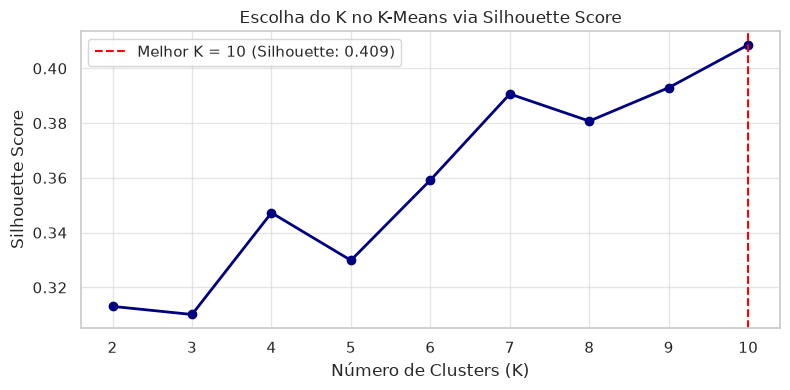

Clusters atribuídos aos estudantes com K = 10.

  PARES COM INDÍCIOS SUSPEITOS DE COLA: 22938


,Estudante_1,Estudante_2,Turma_1,Turma_2,Mesma_Turma,Cluster_KMeans,Questoes_Divergentes,Diferenca_Tempo_Minutos,Horario_1,Horario_2,Pontuacao_1,Pontuacao_2
1040,321.0,1144.0,2i,2i,True,1,0,0.00,2025-07-16 13:41:13,2025-07-16 13:41:21,2800,2800
1041,321.0,893.0,2i,2i,True,1,0,0.00,2025-07-16 13:41:13,2025-07-16 13:41:07,2800,2800
1048,321.0,307.0,2i,2j,False,1,0,0.00,2025-07-16 13:41:13,2025-07-16 13:53:02,2800,2800
1120,321.0,914.0,2i,2n,False,1,0,0.00,2025-07-16 13:41:13,2025-07-16 13:45:35,2800,2800
1303,1010.0,1327.0,2i,2k,False,1,0,0.00,2025-07-16 18:51:05,2025-07-16 18:36:46,2800,2800
...,...,...,...,...,...,...,...,...,...,...,...,...
18511,240.0,764.0,2o,2r,False,1,2,4.37,2025-07-19 08:58:33,2025-07-16 08:06:27,2800,2800
2967,282.0,556.0,2i,2k,False,1,2,9.15,2025-07-18 08:28:33,2025-07-24 17:03:20,2600,2600
10304,556.0,1694.0,2k,2n,False,1,2,9.18,2025-07-24 17:03:20,2025-07-18 08:02:08,2600,2600
2957,282.0,1277.0,2i,2k,False,1,2,9.27,2025-07-18 08:28:33,2025-07-24 18:51:12,2600,2600


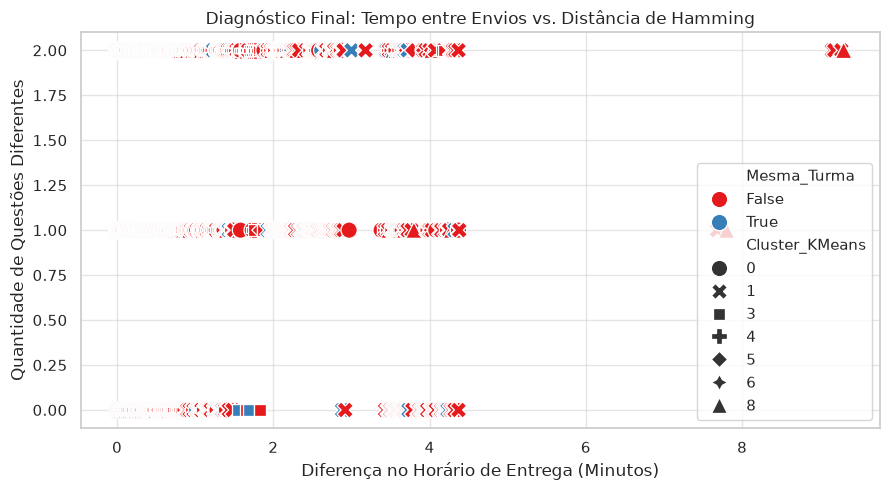

In [15]:
# ==============================================================================
# PIPELINE COMPLETO DE ANÁLISE DE RESPOSTAS E DETEÇÃO DE SUSPEITA DE COLA
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform

# ------------------------------------------------------------------------------
# 1. Configuração do Ambiente e Carregamento dos Dados
# ------------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

# Tenta carregar o ficheiro de dados disponível
file_path = 'data/prova_mat.csv'
try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    try:
        file_path = 'prova_cn_2.csv'
        df = pd.read_csv(file_path)
    except FileNotFoundError:
        file_path = 'prova_cn.csv'
        df = pd.read_csv(file_path)

print(f"--> Ficheiro carregado com sucesso: '{file_path}'")
print(f"--> Total de estudantes registados: {df.shape[0]}\n")

# ------------------------------------------------------------------------------
# 2. Pré-processamento e Codificação One-Hot Encoding
# ------------------------------------------------------------------------------
# Seleção das colunas correspondentes às questões (questões de 0 a 28)
question_cols = [str(i) for i in range(29) if str(i) in df.columns]

# Matriz de respostas tratadas (preenchimento de nulos e conversão para inteiro)
answers_df = df[question_cols].fillna(-1).astype(int)

# Representação das alternativas por One-Hot Encoding
encoder = OneHotEncoder(sparse_output=False)
X_ohe = encoder.fit_transform(answers_df)

print(f"Dimensão original das respostas: {answers_df.shape}")
print(f"Dimensão após One-Hot Encoding: {X_ohe.shape}\n")

# ------------------------------------------------------------------------------
# 3. Agrupamento K-Means e Seleção de K via Silhouette Score
# ------------------------------------------------------------------------------
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_ohe)
    score = silhouette_score(X_ohe, labels)
    silhouette_scores.append(score)

# Identificação do K com maior Silhouette Score
best_k = k_range[np.argmax(silhouette_scores)]

# Gráfico da curva do Silhouette Score
plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_scores, marker='o', color='navy', linewidth=2)
plt.axvline(x=best_k, color='red', linestyle='--', label=f'Melhor K = {best_k} (Silhouette: {max(silhouette_scores):.3f})')
plt.title('Escolha do K no K-Means via Silhouette Score')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Silhouette Score')
plt.legend()
plt.tight_layout()
plt.show()

# Aplicação do K-Means definitivo
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans_final.fit_predict(X_ohe)

print(f"Clusters atribuídos aos estudantes com K = {best_k}.\n")

# ------------------------------------------------------------------------------
# 4. Cálculo da Distância de Hamming (Divergência de Respostas)
# ------------------------------------------------------------------------------
num_questoes = len(question_cols)

# Matriz de distância de Hamming normalizada [0.0 a 1.0]
hamming_norm_matrix = squareform(pdist(answers_df.values, metric='hamming'))

# Conversão para contagem absoluta de questões divergentes entre pares
hamming_count_matrix = np.round(hamming_norm_matrix * num_questoes).astype(int)

# ------------------------------------------------------------------------------
# 5. Análise do Horário de Entrega (Intervalo Temporal em Minutos)
# ------------------------------------------------------------------------------
df['datetime_dt'] = pd.to_datetime(df['datetime'])
timestamps = df['datetime_dt'].astype('int64') // 10**9

# Matriz da diferença absoluta de horário (em minutos) entre submissões
diferenca_tempo_min_matrix = np.abs(timestamps.values[:, None] - timestamps.values[None, :]) / 60.0

# ------------------------------------------------------------------------------
# 6. Identificação dos Pares Suspeitos de Cola e Diagnóstico Final
# ------------------------------------------------------------------------------
n_estudantes = len(df)
pares_suspeitos = []

# Limiares de alerta: até 2 questões divergentes e até 10 minutos de intervalo
MAX_DIVERGENCIA_QUESTOES = 2
MAX_DIFERENCA_TEMPO_MIN = 10.0

for i in range(n_estudantes):
    for j in range(i + 1, n_estudantes):
        q_diff = hamming_count_matrix[i, j]
        t_diff = diferenca_tempo_min_matrix[i, j]
        mesmo_cluster = (df.loc[i, 'cluster_kmeans'] == df.loc[j, 'cluster_kmeans'])
        mesma_turma = (df.loc[i, 'serie_turma'] == df.loc[j, 'serie_turma']) if 'serie_turma' in df.columns else True

        if q_diff <= MAX_DIVERGENCIA_QUESTOES and t_diff <= MAX_DIFERENCA_TEMPO_MIN:
            pares_suspeitos.append({
                'Estudante_1': df.loc[i, 'estudante'],
                'Estudante_2': df.loc[j, 'estudante'],
                'Turma_1': df.loc[i, 'serie_turma'] if 'serie_turma' in df.columns else 'N/A',
                'Turma_2': df.loc[j, 'serie_turma'] if 'serie_turma' in df.columns else 'N/A',
                'Mesma_Turma': mesma_turma,
                'Cluster_KMeans': df.loc[i, 'cluster_kmeans'],
                'Questoes_Divergentes': q_diff,
                'Diferenca_Tempo_Minutos': round(t_diff, 2),
                'Horario_1': df.loc[i, 'datetime'],
                'Horario_2': df.loc[j, 'datetime'],
                'Pontuacao_1': df.loc[i, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A',
                'Pontuacao_2': df.loc[j, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A'
            })

df_suspeitos = pd.DataFrame(pares_suspeitos)

if not df_suspeitos.empty:
    df_suspeitos = df_suspeitos.sort_values(by=['Questoes_Divergentes', 'Diferenca_Tempo_Minutos'])
    print("=========================================================")
    print(f"  PARES COM INDÍCIOS SUSPEITOS DE COLA: {len(df_suspeitos)}")
    print("=========================================================")
    display(df_suspeitos)

    # Gráfico de Dispersão: Diferença de Tempo vs. Distância de Hamming
    plt.figure(figsize=(9, 5))
    sns.scatterplot(
        data=df_suspeitos,
        x='Diferenca_Tempo_Minutos',
        y='Questoes_Divergentes',
        hue='Mesma_Turma',
        style='Cluster_KMeans',
        s=140,
        palette='Set1'
    )
    plt.title('Diagnóstico Final: Tempo entre Envios vs. Distância de Hamming')
    plt.xlabel('Diferença no Horário de Entrega (Minutos)')
    plt.ylabel('Quantidade de Questões Diferentes')
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum par atendeu aos critérios de suspeita estabelecidos.")

--> Ficheiro carregado com sucesso: 'data/prova_mat.csv'
--> Total de estudantes registados: 274

Dimensão original das respostas: (274, 15)
Dimensão após One-Hot Encoding: (274, 72)



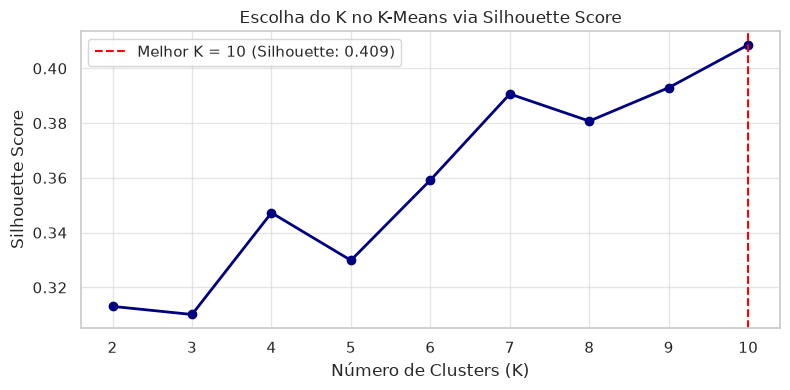

Clusters atribuídos aos estudantes com K = 10.

  PARES DA MESMA TURMA COM INDÍCIOS SUSPEITOS DE COLA: 1951


,Estudante_1,Estudante_2,Turma,Cluster_KMeans,Questoes_Divergentes,Diferenca_Tempo_Minutos,Horario_1,Horario_2,Pontuacao_1,Pontuacao_2
89,321.0,1144.0,2i,1,0,0.00,2025-07-16 13:41:13,2025-07-16 13:41:21,2800,2800
90,321.0,893.0,2i,1,0,0.00,2025-07-16 13:41:13,2025-07-16 13:41:07,2800,2800
166,1144.0,893.0,2i,1,0,0.00,2025-07-16 13:41:21,2025-07-16 13:41:07,2800,2800
333,1432.0,1510.0,2j,6,0,0.00,2025-07-16 21:37:16,2025-07-16 21:37:14,2200,2200
484,1607.0,260.0,2k,1,0,0.00,2025-07-16 19:40:55,2025-07-16 19:42:28,2800,2800
...,...,...,...,...,...,...,...,...,...,...
1126,1281.0,240.0,2o,8,2,3.53,2025-07-16 22:09:28,2025-07-19 08:58:33,2400,2800
1196,240.0,1291.0,2o,1,2,3.58,2025-07-19 08:58:33,2025-07-16 21:21:57,2800,2400
1156,134.0,240.0,2o,8,2,3.62,2025-07-16 20:37:56,2025-07-19 08:58:33,2400,2800
1197,240.0,573.0,2o,1,2,3.68,2025-07-19 08:58:33,2025-07-16 19:28:23,2800,2400


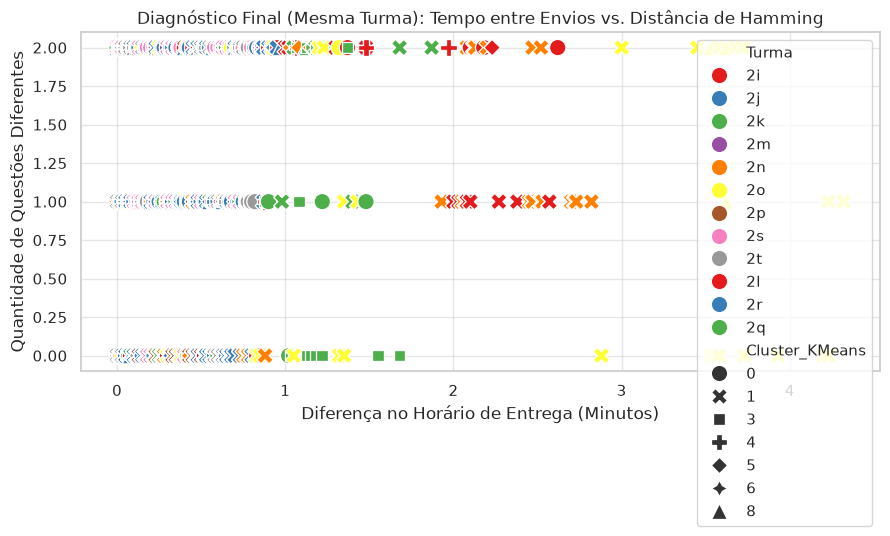

In [17]:
# ==============================================================================
# PIPELINE COMPLETO DE ANÁLISE DE RESPOSTAS E DETEÇÃO DE SUSPEITA DE COLA
# (COMPARAÇÃO RESTRITA A ESTUDANTES DA MESMA TURMA)
# ==============================================================================

import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import OneHotEncoder

# ------------------------------------------------------------------------------
# 1. Configuração do Ambiente e Carregamento dos Dados
# ------------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

# Tenta carregar o ficheiro de dados disponível
file_path = "data/prova_mat.csv"
try:
  df = pd.read_csv(file_path)
except FileNotFoundError:
  try:
    file_path = "prova_cn_2.csv"
    df = pd.read_csv(file_path)
  except FileNotFoundError:
    file_path = "prova_cn.csv"
    df = pd.read_csv(file_path)

print(f"--> Ficheiro carregado com sucesso: '{file_path}'")
print(f"--> Total de estudantes registados: {df.shape[0]}\n")

# ------------------------------------------------------------------------------
# 2. Pré-processamento e Codificação One-Hot Encoding
# ------------------------------------------------------------------------------
# Seleção das colunas correspondentes às questões (questões de 0 a 28)
question_cols = [str(i) for i in range(29) if str(i) in df.columns]

# Matriz de respostas tratadas (preenchimento de nulos e conversão para inteiro)
answers_df = df[question_cols].fillna(-1).astype(int)

# Representação das alternativas por One-Hot Encoding
encoder = OneHotEncoder(sparse_output=False)
X_ohe = encoder.fit_transform(answers_df)

print(f"Dimensão original das respostas: {answers_df.shape}")
print(f"Dimensão após One-Hot Encoding: {X_ohe.shape}\n")

# ------------------------------------------------------------------------------
# 3. Agrupamento K-Means e Seleção de K via Silhouette Score
# ------------------------------------------------------------------------------
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = kmeans.fit_predict(X_ohe)
  score = silhouette_score(X_ohe, labels)
  silhouette_scores.append(score)

# Identificação do K com maior Silhouette Score
best_k = k_range[np.argmax(silhouette_scores)]

# Gráfico da curva do Silhouette Score
plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_scores, marker="o", color="navy", linewidth=2)
plt.axvline(
    x=best_k,
    color="red",
    linestyle="--",
    label=f"Melhor K = {best_k} (Silhouette: {max(silhouette_scores):.3f})",
)
plt.title("Escolha do K no K-Means via Silhouette Score")
plt.xlabel("Número de Clusters (K)")
plt.ylabel("Silhouette Score")
plt.legend()
plt.tight_layout()
plt.show()

# Aplicação do K-Means definitivo
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["cluster_kmeans"] = kmeans_final.fit_predict(X_ohe)

print(f"Clusters atribuídos aos estudantes com K = {best_k}.\n")

# ------------------------------------------------------------------------------
# 4. Cálculo da Distância de Hamming (Divergência de Respostas)
# ------------------------------------------------------------------------------
num_questoes = len(question_cols)

# Matriz de distância de Hamming normalizada [0.0 a 1.0]
hamming_norm_matrix = squareform(pdist(answers_df.values, metric="hamming"))

# Conversão para contagem absoluta de questões divergentes entre pares
hamming_count_matrix = np.round(hamming_norm_matrix * num_questoes).astype(int)

# ------------------------------------------------------------------------------
# 5. Análise do Horário de Entrega (Intervalo Temporal em Minutos)
# ------------------------------------------------------------------------------
df["datetime_dt"] = pd.to_datetime(df["datetime"])
timestamps = df["datetime_dt"].astype("int64") // 10**9

# Matriz da diferença absoluta de horário (em minutos) entre submissões
diferenca_tempo_min_matrix = (
    np.abs(timestamps.values[:, None] - timestamps.values[None, :]) / 60.0
)

# ------------------------------------------------------------------------------
# 6. Identificação dos Pares Suspeitos de Cola (Apenas Mesma Turma)
# ------------------------------------------------------------------------------
n_estudantes = len(df)
pares_suspeitos = []

# Limiares de alerta: até 2 questões divergentes e até 10 minutos de intervalo
MAX_DIVERGENCIA_QUESTOES = 2
MAX_DIFERENCA_TEMPO_MIN = 10.0

for i in range(n_estudantes):
  for j in range(i + 1, n_estudantes):
    # FILTRO ESTRITO: Pula a comparação se os estudantes forem de turmas diferentes
    mesma_turma = (
        (df.loc[i, "serie_turma"] == df.loc[j, "serie_turma"])
        if "serie_turma" in df.columns
        else True
    )
    if not mesma_turma:
      continue

    q_diff = hamming_count_matrix[i, j]
    t_diff = diferenca_tempo_min_matrix[i, j]
    mesmo_cluster = (
        df.loc[i, "cluster_kmeans"] == df.loc[j, "cluster_kmeans"]
    )

    if q_diff <= MAX_DIVERGENCIA_QUESTOES and t_diff <= MAX_DIFERENCA_TEMPO_MIN:
      pares_suspeitos.append({
          "Estudante_1": df.loc[i, "estudante"],
          "Estudante_2": df.loc[j, "estudante"],
          "Turma": (
              df.loc[i, "serie_turma"] if "serie_turma" in df.columns else "N/A"
          ),
          "Cluster_KMeans": df.loc[i, "cluster_kmeans"],
          "Questoes_Divergentes": q_diff,
          "Diferenca_Tempo_Minutos": round(t_diff, 2),
          "Horario_1": df.loc[i, "datetime"],
          "Horario_2": df.loc[j, "datetime"],
          "Pontuacao_1": (
              df.loc[i, "pontuacao"] if "pontuacao" in df.columns else "N/A"
          ),
          "Pontuacao_2": (
              df.loc[j, "pontuacao"] if "pontuacao" in df.columns else "N/A"
          ),
      })

df_suspeitos = pd.DataFrame(pares_suspeitos)

if not df_suspeitos.empty:
  df_suspeitos = df_suspeitos.sort_values(
      by=["Questoes_Divergentes", "Diferenca_Tempo_Minutos"]
  )
  print("=========================================================")
  print(
      "  PARES DA MESMA TURMA COM INDÍCIOS SUSPEITOS DE COLA:"
      f" {len(df_suspeitos)}"
  )
  print("=========================================================")
  display(df_suspeitos)

  # Gráfico de Dispersão: Diferença de Tempo vs. Distância de Hamming por Turma
  plt.figure(figsize=(9, 5))
  sns.scatterplot(
      data=df_suspeitos,
      x="Diferenca_Tempo_Minutos",
      y="Questoes_Divergentes",
      hue="Turma",
      style="Cluster_KMeans",
      s=140,
      palette="Set1",
  )
  plt.title(
      "Diagnóstico Final (Mesma Turma): Tempo entre Envios vs. Distância de"
      " Hamming"
  )
  plt.xlabel("Diferença no Horário de Entrega (Minutos)")
  plt.ylabel("Quantidade de Questões Diferentes")
  plt.tight_layout()
  plt.show()
else:
  print(
      "Nenhum par da mesma turma atendeu aos critérios de suspeita"
      " estabelecidos."
  )

--> Ficheiro carregado com sucesso: 'data/prova_hum.csv'
--> Total de estudantes registados: 147

Dimensão original das respostas: (147, 29)
Dimensão após One-Hot Encoding: (147, 134)

O melhor K (2) é o primeiro valor avaliado. Exibindo K=2 e valores posteriores.


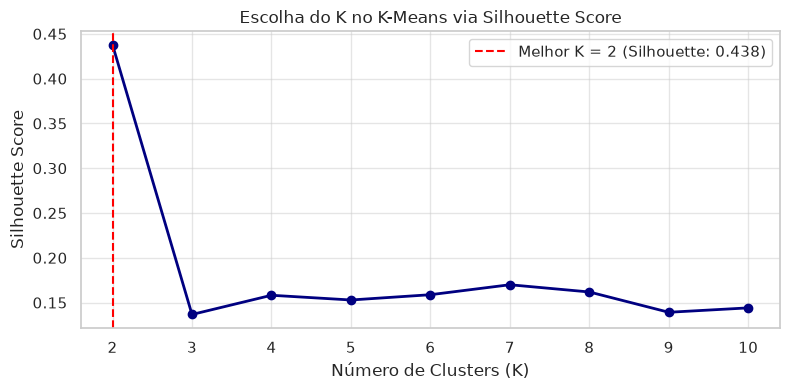

Clusters atribuídos aos estudantes com K = 2.

  PARES DA MESMA TURMA COM INDÍCIOS SUSPEITOS DE COLA: 851


,Estudante_1,Estudante_2,Turma,Cluster_KMeans,Questoes_Divergentes,Diferenca_Tempo_Minutos,Horario_1,Horario_2,Pontuacao_1,Pontuacao_2
10,83,667,2e,0,0,0.00,2025-07-17 19:29:57,2025-07-17 19:25:01,2775,2700
41,507,148,2e,1,0,0.00,2025-07-17 21:30:28,2025-07-17 21:30:28,2250,2250
212,1282,1515,2f,0,0,0.00,2025-07-17 14:09:22,2025-07-17 14:13:46,2850,2775
288,1544,1537,2f,0,0,0.00,2025-07-17 11:37:06,2025-07-17 11:37:05,2700,2700
330,716,349,2f,0,0,0.00,2025-07-17 19:29:30,2025-07-17 19:31:40,2700,2700
...,...,...,...,...,...,...,...,...,...,...
104,419,462,2e,0,2,1.00,2025-07-18 07:41:54,2025-07-17 14:55:52,2325,2850
175,1058,1659,2e,0,2,1.00,2025-07-18 07:27:41,2025-07-17 14:43:50,2850,2550
399,800,1213,2f,0,2,1.07,2025-07-17 08:54:38,2025-07-18 02:38:53,2550,2775
249,380,1213,2f,0,2,1.10,2025-07-17 08:26:56,2025-07-18 02:38:53,2850,2775


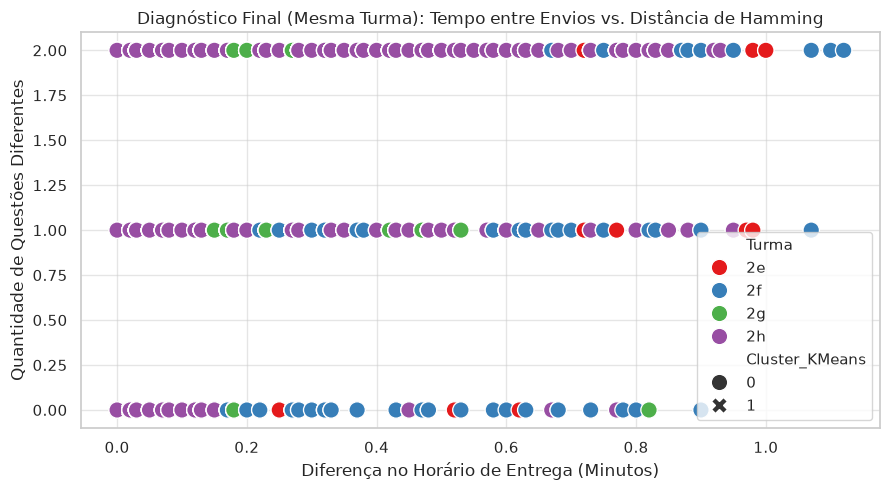

In [21]:
# ==============================================================================
# PIPELINE COMPLETO DE ANÁLISE DE RESPOSTAS E DETEÇÃO DE SUSPEITA DE COLA
# (COMPARAÇÃO RESTRITA À MESMA TURMA + GRÁFICO DE SILHUETA ADAPTATIVO)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform

# ------------------------------------------------------------------------------
# 1. Configuração do Ambiente e Carregamento dos Dados
# ------------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

# Tenta carregar o ficheiro de dados disponível
file_path = 'data/prova_hum.csv'
try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    try:
        file_path = 'prova_cn_2.csv'
        df = pd.read_csv(file_path)
    except FileNotFoundError:
        file_path = 'prova_cn.csv'
        df = pd.read_csv(file_path)

print(f"--> Ficheiro carregado com sucesso: '{file_path}'")
print(f"--> Total de estudantes registados: {df.shape[0]}\n")

# ------------------------------------------------------------------------------
# 2. Pré-processamento e Codificação One-Hot Encoding
# ------------------------------------------------------------------------------
# Seleção das colunas correspondentes às questões (0 a 28)
question_cols = [str(i) for i in range(29) if str(i) in df.columns]

# Matriz de respostas tratadas
answers_df = df[question_cols].fillna(-1).astype(int)

# Representação das alternativas por One-Hot Encoding
encoder = OneHotEncoder(sparse_output=False)
X_ohe = encoder.fit_transform(answers_df)

print(f"Dimensão original das respostas: {answers_df.shape}")
print(f"Dimensão após One-Hot Encoding: {X_ohe.shape}\n")

# ------------------------------------------------------------------------------
# 3. Agrupamento K-Means e Seleção de K via Silhouette Score
# ------------------------------------------------------------------------------
silhouette_scores = []
k_range = list(range(2, 11))

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_ohe)
    score = silhouette_score(X_ohe, labels)
    silhouette_scores.append(score)

# Identificação do K com maior Silhouette Score
best_k_idx = np.argmax(silhouette_scores)
best_k = k_range[best_k_idx]

# Lógica para exibição do gráfico:
# - Se o melhor K é o primeiro (índice 0), exibe a partir dele e os posteriores.
# - Se o melhor K é intermediário, exibe valores anteriores, o melhor K e os posteriores.
if best_k_idx == 0:
    plot_k = k_range
    plot_scores = silhouette_scores
    print(f"O melhor K ({best_k}) é o primeiro valor avaliado. Exibindo K={best_k} e valores posteriores.")
else:
    plot_k = k_range
    plot_scores = silhouette_scores
    print(f"O melhor K ({best_k}) é intermediário. Exibindo valores anteriores, K={best_k} e posteriores.")

# Gráfico da curva do Silhouette Score
plt.figure(figsize=(8, 4))
plt.plot(plot_k, plot_scores, marker='o', color='navy', linewidth=2)
plt.axvline(x=best_k, color='red', linestyle='--', label=f'Melhor K = {best_k} (Silhouette: {silhouette_scores[best_k_idx]:.3f})')
plt.title('Escolha do K no K-Means via Silhouette Score')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(plot_k)
plt.legend()
plt.tight_layout()
plt.show()

# Aplicação do K-Means definitivo
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans_final.fit_predict(X_ohe)

print(f"Clusters atribuídos aos estudantes com K = {best_k}.\n")

# ------------------------------------------------------------------------------
# 4. Cálculo da Distância de Hamming (Divergência de Respostas)
# ------------------------------------------------------------------------------
num_questoes = len(question_cols)

# Matriz de distância de Hamming normalizada [0.0 a 1.0]
hamming_norm_matrix = squareform(pdist(answers_df.values, metric='hamming'))

# Conversão para contagem absoluta de questões divergentes entre pares
hamming_count_matrix = np.round(hamming_norm_matrix * num_questoes).astype(int)

# ------------------------------------------------------------------------------
# 5. Análise do Horário de Entrega (Intervalo Temporal em Minutos)
# ------------------------------------------------------------------------------
df['datetime_dt'] = pd.to_datetime(df['datetime'])
timestamps = df['datetime_dt'].astype('int64') // 10**9

# Matriz da diferença absoluta de horário (em minutos) entre submissões
diferenca_tempo_min_matrix = np.abs(timestamps.values[:, None] - timestamps.values[None, :]) / 60.0

# ------------------------------------------------------------------------------
# 6. Identificação dos Pares Suspeitos de Cola (Apenas Mesma Turma)
# ------------------------------------------------------------------------------
n_estudantes = len(df)
pares_suspeitos = []

# Limiares de alerta: até 2 questões divergentes e até 10 minutos de intervalo
MAX_DIVERGENCIA_QUESTOES = 2
MAX_DIFERENCA_TEMPO_MIN = 10.0

for i in range(n_estudantes):
    for j in range(i + 1, n_estudantes):
        # FILTRO ESTRITO: Compara apenas estudantes da MESMA TURMA
        mesma_turma = (df.loc[i, 'serie_turma'] == df.loc[j, 'serie_turma']) if 'serie_turma' in df.columns else True
        if not mesma_turma:
            continue

        q_diff = hamming_count_matrix[i, j]
        t_diff = diferenca_tempo_min_matrix[i, j]
        mesmo_cluster = (df.loc[i, 'cluster_kmeans'] == df.loc[j, 'cluster_kmeans'])

        if q_diff <= MAX_DIVERGENCIA_QUESTOES and t_diff <= MAX_DIFERENCA_TEMPO_MIN:
            pares_suspeitos.append({
                'Estudante_1': df.loc[i, 'estudante'],
                'Estudante_2': df.loc[j, 'estudante'],
                'Turma': df.loc[i, 'serie_turma'] if 'serie_turma' in df.columns else 'N/A',
                'Cluster_KMeans': df.loc[i, 'cluster_kmeans'],
                'Questoes_Divergentes': q_diff,
                'Diferenca_Tempo_Minutos': round(t_diff, 2),
                'Horario_1': df.loc[i, 'datetime'],
                'Horario_2': df.loc[j, 'datetime'],
                'Pontuacao_1': df.loc[i, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A',
                'Pontuacao_2': df.loc[j, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A'
            })

df_suspeitos = pd.DataFrame(pares_suspeitos)

if not df_suspeitos.empty:
    df_suspeitos = df_suspeitos.sort_values(by=['Questoes_Divergentes', 'Diferenca_Tempo_Minutos'])
    print("=========================================================")
    print(f"  PARES DA MESMA TURMA COM INDÍCIOS SUSPEITOS DE COLA: {len(df_suspeitos)}")
    print("=========================================================")
    display(df_suspeitos)

    # Gráfico de Dispersão: Diferença de Tempo vs. Distância de Hamming por Turma
    plt.figure(figsize=(9, 5))
    sns.scatterplot(
        data=df_suspeitos,
        x='Diferenca_Tempo_Minutos',
        y='Questoes_Divergentes',
        hue='Turma',
        style='Cluster_KMeans',
        s=140,
        palette='Set1'
    )
    plt.title('Diagnóstico Final (Mesma Turma): Tempo entre Envios vs. Distância de Hamming')
    plt.xlabel('Diferença no Horário de Entrega (Minutos)')
    plt.ylabel('Quantidade de Questões Diferentes')
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum par da mesma turma atendeu aos critérios de suspeita estabelecidos.")

--> Ficheiro carregado com sucesso: 'data/prova_hum.csv'
--> Total de estudantes registados: 147

Dimensão original das respostas: (147, 29)
Dimensão após One-Hot Encoding: (147, 134)

O melhor K (2) é o primeiro valor avaliado. Exibindo K=2 e valores posteriores.


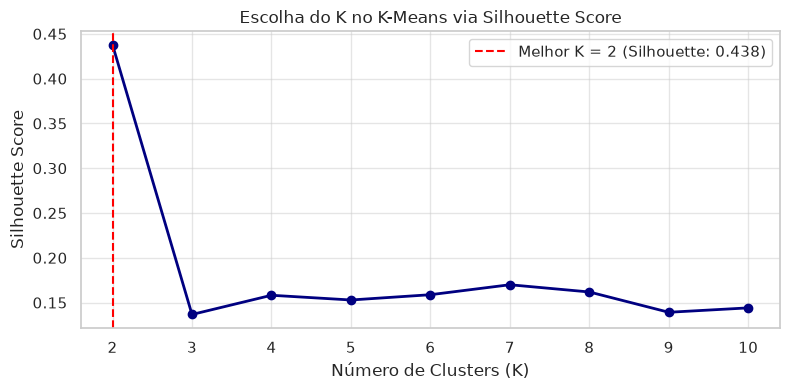

Clusters atribuídos aos estudantes com K = 2.

  PARES DA MESMA TURMA COM INDÍCIOS SUSPEITOS DE COLA: 851



,Estudante_1,Estudante_2,Turma,Cluster_KMeans,Questoes_Divergentes,Diferenca_Tempo_Minutos,Horario_1,Horario_2,Pontuacao_1,Pontuacao_2
10,83,667,2e,0,0,0.00,2025-07-17 19:29:57,2025-07-17 19:25:01,2775,2775
41,507,148,2e,1,0,0.00,2025-07-17 21:30:28,2025-07-17 21:30:28,2250,2250
212,1282,1515,2f,0,0,0.00,2025-07-17 14:09:22,2025-07-17 14:13:46,2850,2850
288,1544,1537,2f,0,0,0.00,2025-07-17 11:37:06,2025-07-17 11:37:05,2700,2700
330,716,349,2f,0,0,0.00,2025-07-17 19:29:30,2025-07-17 19:31:40,2700,2700
...,...,...,...,...,...,...,...,...,...,...
104,419,462,2e,0,2,1.00,2025-07-18 07:41:54,2025-07-17 14:55:52,2325,2325
175,1058,1659,2e,0,2,1.00,2025-07-18 07:27:41,2025-07-17 14:43:50,2850,2850
399,800,1213,2f,0,2,1.07,2025-07-17 08:54:38,2025-07-18 02:38:53,2550,2550
249,380,1213,2f,0,2,1.10,2025-07-17 08:26:56,2025-07-18 02:38:53,2850,2850


--> A gerar gráficos individuais por turma...


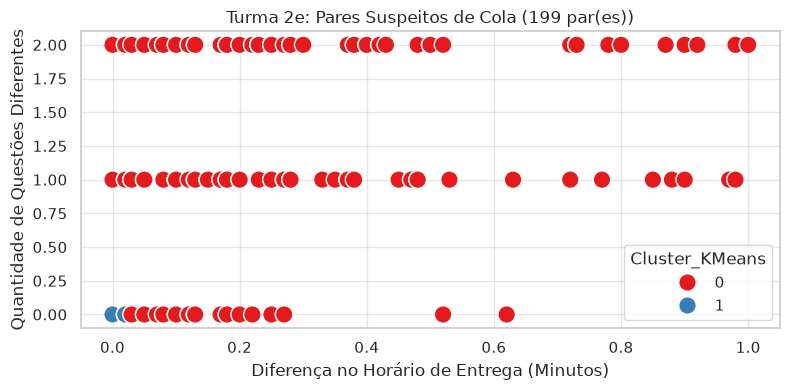

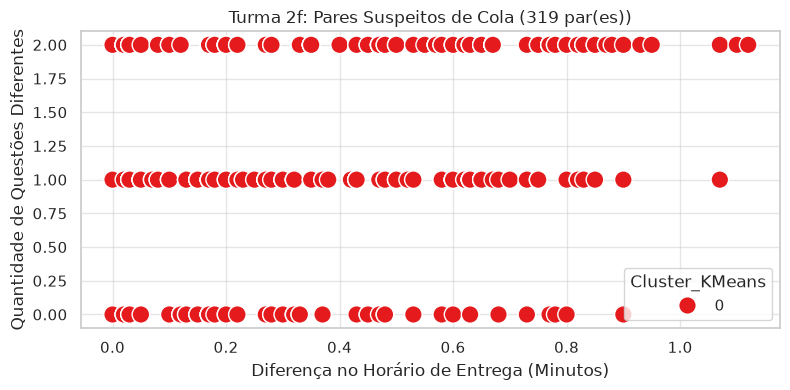

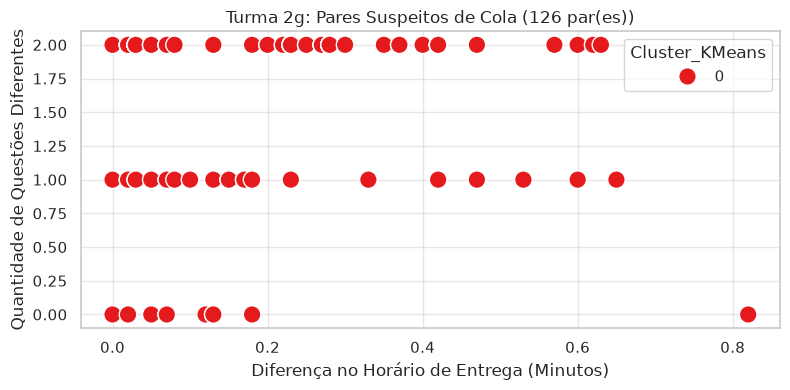

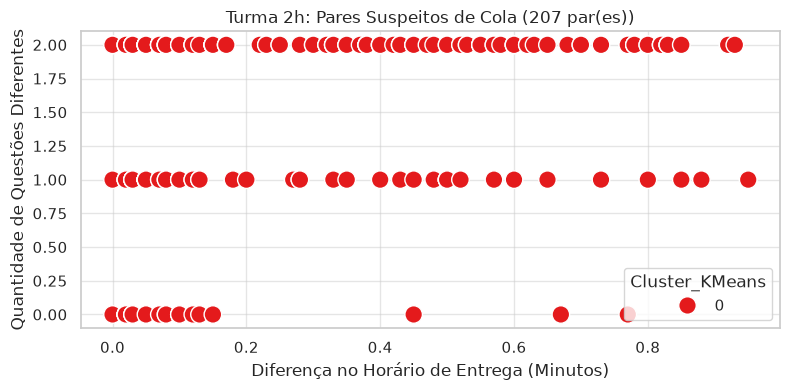

In [23]:
# ==============================================================================
# PIPELINE COMPLETO DE ANÁLISE DE RESPOSTAS E DETEÇÃO DE SUSPEITA DE COLA
# (GRÁFICOS INDIVIDUAIS POR TURMA)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform

# ------------------------------------------------------------------------------
# 1. Configuração do Ambiente e Carregamento dos Dados
# ------------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

# Tenta carregar o ficheiro de dados disponível
file_path = 'data/prova_hum.csv'
try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    try:
        file_path = 'prova_cn_2.csv'
        df = pd.read_csv(file_path)
    except FileNotFoundError:
        file_path = 'prova_cn.csv'
        df = pd.read_csv(file_path)

print(f"--> Ficheiro carregado com sucesso: '{file_path}'")
print(f"--> Total de estudantes registados: {df.shape[0]}\n")

# ------------------------------------------------------------------------------
# 2. Pré-processamento e Codificação One-Hot Encoding
# ------------------------------------------------------------------------------
# Seleção das colunas correspondentes às questões (0 a 28)
question_cols = [str(i) for i in range(29) if str(i) in df.columns]

# Matriz de respostas tratadas
answers_df = df[question_cols].fillna(-1).astype(int)

# Representação das alternativas por One-Hot Encoding
encoder = OneHotEncoder(sparse_output=False)
X_ohe = encoder.fit_transform(answers_df)

print(f"Dimensão original das respostas: {answers_df.shape}")
print(f"Dimensão após One-Hot Encoding: {X_ohe.shape}\n")

# ------------------------------------------------------------------------------
# 3. Agrupamento K-Means e Seleção de K via Silhouette Score
# ------------------------------------------------------------------------------
silhouette_scores = []
k_range = list(range(2, 11))

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_ohe)
    score = silhouette_score(X_ohe, labels)
    silhouette_scores.append(score)

# Identificação do K com maior Silhouette Score
best_k_idx = np.argmax(silhouette_scores)
best_k = k_range[best_k_idx]

# Lógica para exibição do gráfico:
# - Se o melhor K for o primeiro (índice 0), exibe a partir dele e os posteriores.
# - Se for intermediário, exibe valores anteriores, o melhor K e os posteriores.
if best_k_idx == 0:
    plot_k = k_range
    plot_scores = silhouette_scores
    print(f"O melhor K ({best_k}) é o primeiro valor avaliado. Exibindo K={best_k} e valores posteriores.")
else:
    plot_k = k_range
    plot_scores = silhouette_scores
    print(f"O melhor K ({best_k}) é intermediário. Exibindo valores anteriores, K={best_k} e posteriores.")

# Gráfico da curva do Silhouette Score
plt.figure(figsize=(8, 4))
plt.plot(plot_k, plot_scores, marker='o', color='navy', linewidth=2)
plt.axvline(x=best_k, color='red', linestyle='--', label=f'Melhor K = {best_k} (Silhouette: {silhouette_scores[best_k_idx]:.3f})')
plt.title('Escolha do K no K-Means via Silhouette Score')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(plot_k)
plt.legend()
plt.tight_layout()
plt.show()

# Aplicação do K-Means definitivo
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans_final.fit_predict(X_ohe)

print(f"Clusters atribuídos aos estudantes com K = {best_k}.\n")

# ------------------------------------------------------------------------------
# 4. Cálculo da Distância de Hamming (Divergência de Respostas)
# ------------------------------------------------------------------------------
num_questoes = len(question_cols)

# Matriz de distância de Hamming normalizada [0.0 a 1.0]
hamming_norm_matrix = squareform(pdist(answers_df.values, metric='hamming'))

# Conversão para contagem absoluta de questões divergentes entre pares
hamming_count_matrix = np.round(hamming_norm_matrix * num_questoes).astype(int)

# ------------------------------------------------------------------------------
# 5. Análise do Horário de Entrega (Intervalo Temporal em Minutos)
# ------------------------------------------------------------------------------
df['datetime_dt'] = pd.to_datetime(df['datetime'])
timestamps = df['datetime_dt'].astype('int64') // 10**9

# Matriz da diferença absoluta de horário (em minutos) entre submissões
diferenca_tempo_min_matrix = np.abs(timestamps.values[:, None] - timestamps.values[None, :]) / 60.0

# ------------------------------------------------------------------------------
# 6. Identificação dos Pares Suspeitos de Cola (Apenas Mesma Turma)
# ------------------------------------------------------------------------------
n_estudantes = len(df)
pares_suspeitos = []

# Limiares de alerta: até 2 questões divergentes e até 10 minutos de intervalo
MAX_DIVERGENCIA_QUESTOES = 2
MAX_DIFERENCA_TEMPO_MIN = 10.0

for i in range(n_estudantes):
    for j in range(i + 1, n_estudantes):
        # FILTRO ESTRITO: Compara apenas estudantes da MESMA TURMA
        mesma_turma = (df.loc[i, 'serie_turma'] == df.loc[j, 'serie_turma']) if 'serie_turma' in df.columns else True
        if not mesma_turma:
            continue

        q_diff = hamming_count_matrix[i, j]
        t_diff = diferenca_tempo_min_matrix[i, j]
        mesmo_cluster = (df.loc[i, 'cluster_kmeans'] == df.loc[j, 'cluster_kmeans'])

        if q_diff <= MAX_DIVERGENCIA_QUESTOES and t_diff <= MAX_DIFERENCA_TEMPO_MIN:
            pares_suspeitos.append({
                'Estudante_1': df.loc[i, 'estudante'],
                'Estudante_2': df.loc[j, 'estudante'],
                'Turma': df.loc[i, 'serie_turma'] if 'serie_turma' in df.columns else 'N/A',
                'Cluster_KMeans': df.loc[i, 'cluster_kmeans'],
                'Questoes_Divergentes': q_diff,
                'Diferenca_Tempo_Minutos': round(t_diff, 2),
                'Horario_1': df.loc[i, 'datetime'],
                'Horario_2': df.loc[j, 'datetime'],
                'Pontuacao_1': df.loc[i, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A',
                'Pontuacao_2': df.loc[i, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A'
            })

df_suspeitos = pd.DataFrame(pares_suspeitos)

if not df_suspeitos.empty:
    df_suspeitos = df_suspeitos.sort_values(by=['Questoes_Divergentes', 'Diferenca_Tempo_Minutos'])
    print("=========================================================")
    print(f"  PARES DA MESMA TURMA COM INDÍCIOS SUSPEITOS DE COLA: {len(df_suspeitos)}")
    print("=========================================================\n")
    display(df_suspeitos)
else:
    print("Nenhum par da mesma turma atendeu aos critérios de suspeita estabelecidos.\n")

# ------------------------------------------------------------------------------
# 7. GERAÇÃO DE UM GRÁFICO INDIVIDUAL POR TURMA
# ------------------------------------------------------------------------------
turmas_unicas = sorted(df['serie_turma'].unique()) if 'serie_turma' in df.columns else ['N/A']

print("--> A gerar gráficos individuais por turma...")

for turma in turmas_unicas:
    plt.figure(figsize=(8, 4))

    # Filtra os pares suspeitos pertencentes à turma atual
    df_turma = df_suspeitos[df_suspeitos['Turma'] == turma] if not df_suspeitos.empty else pd.DataFrame()

    if not df_turma.empty:
        sns.scatterplot(
            data=df_turma,
            x='Diferenca_Tempo_Minutos',
            y='Questoes_Divergentes',
            hue='Cluster_KMeans',
            s=160,
            palette='Set1'
        )
        plt.title(f'Turma {turma}: Pares Suspeitos de Cola ({len(df_turma)} par(es))')
        plt.xlabel('Diferença no Horário de Entrega (Minutos)')
        plt.ylabel('Quantidade de Questões Diferentes')
    else:
        # Apresenta mensagem explicativa se a turma não tiver pares suspeitos
        plt.text(0.5, 0.5, f'Nenhum par suspeito identificado na Turma {turma}',
                 horizontalalignment='center', verticalalignment='center',
                 transform=plt.gca().transAxes, fontsize=12, color='gray')
        plt.title(f'Turma {turma}: Sem Suspeitas Detectadas')
        plt.xlabel('Diferença no Horário de Entrega (Minutos)')
        plt.ylabel('Quantidade de Questões Diferentes')

    plt.tight_layout()
    plt.show()

--> Ficheiro carregado com sucesso: 'data/prova_mat.csv'
--> Total de estudantes registados: 274

Dimensão original das respostas: (274, 15)
Dimensão após One-Hot Encoding: (274, 72)

O melhor K (10) é intermediário. Exibindo valores anteriores, K=10 e posteriores.


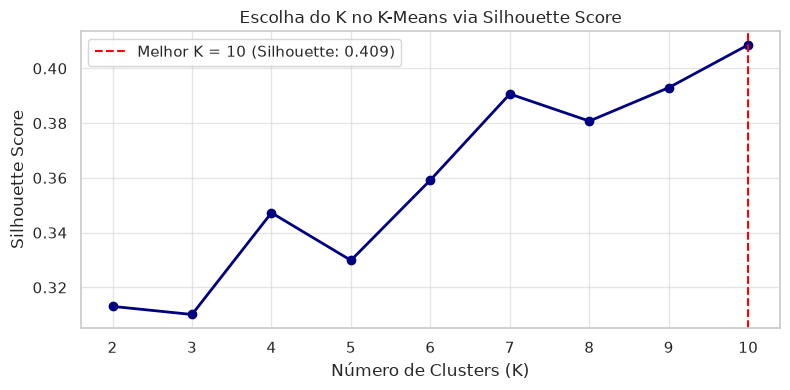

Clusters atribuídos aos estudantes com K = 10.

  PARES DA MESMA TURMA COM INDÍCIOS SUSPEITOS DE COLA: 1992



,Estudante_1,Estudante_2,Par_Estudantes,Turma,Cluster_KMeans,Questoes_Divergentes,Pontuacao_1,Pontuacao_2
10,370.0,1446.0,370.0 - 1446.0,2i,0,0,2400,2400
17,1382.0,201.0,1382.0 - 201.0,2i,0,0,2600,2600
21,1382.0,591.0,1382.0 - 591.0,2i,0,0,2600,2600
36,344.0,321.0,344.0 - 321.0,2i,1,0,2800,2800
37,344.0,1010.0,344.0 - 1010.0,2i,1,0,2800,2800
...,...,...,...,...,...,...,...,...
1981,801.0,1122.0,801.0 - 1122.0,2t,4,2,2400,2800
1982,801.0,658.0,801.0 - 658.0,2t,4,2,2400,2800
1985,334.0,368.0,334.0 - 368.0,2t,1,2,2800,2400
1988,1122.0,368.0,1122.0 - 368.0,2t,1,2,2800,2400


--> A gerar gráficos individuais de divergência por turma...


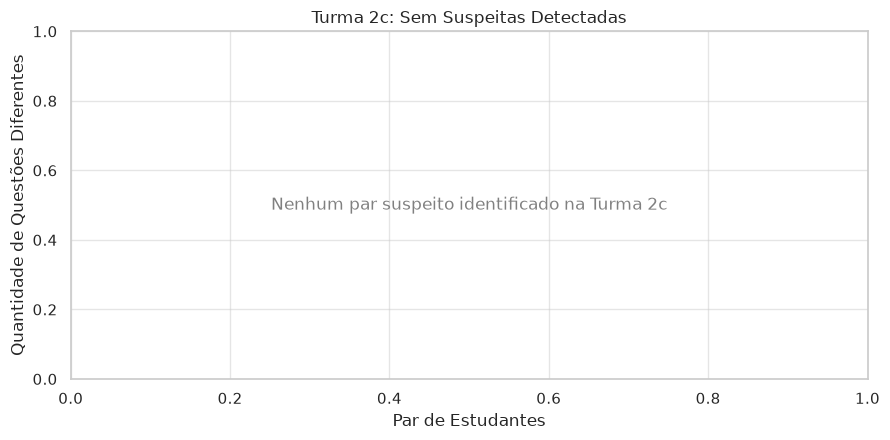

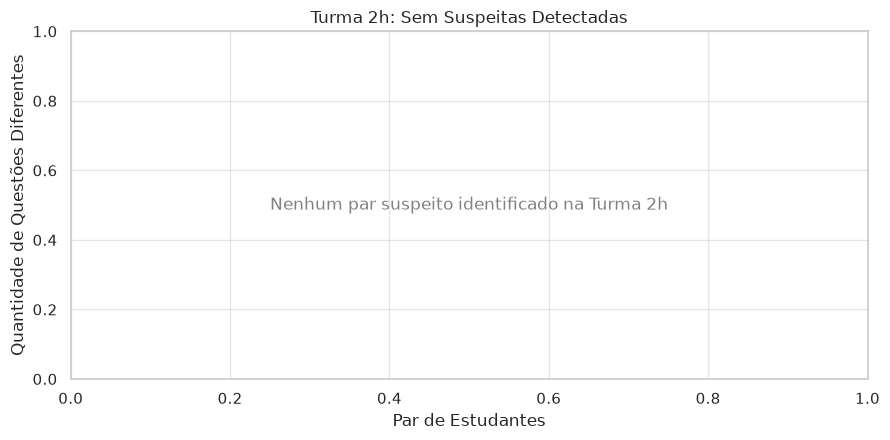

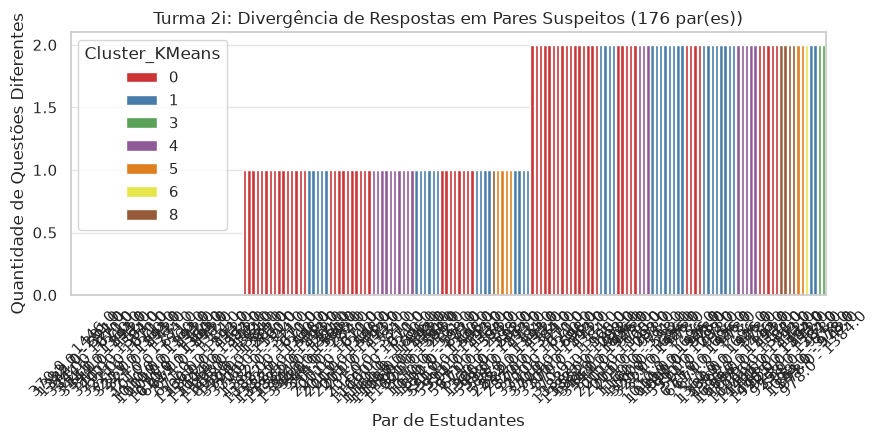

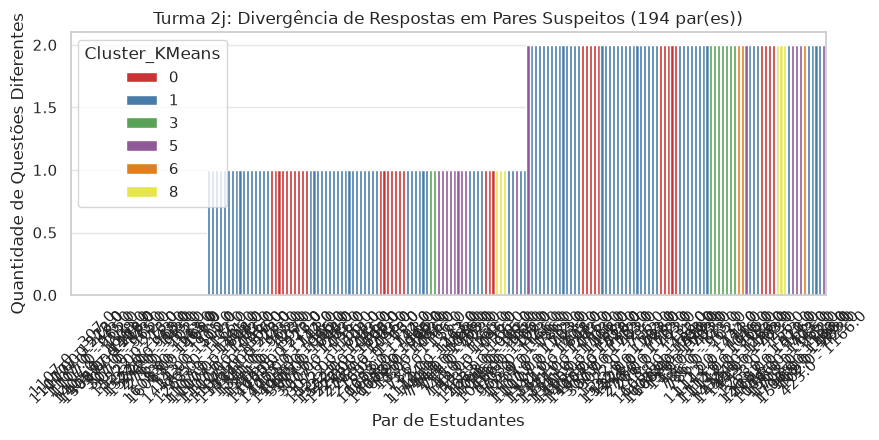

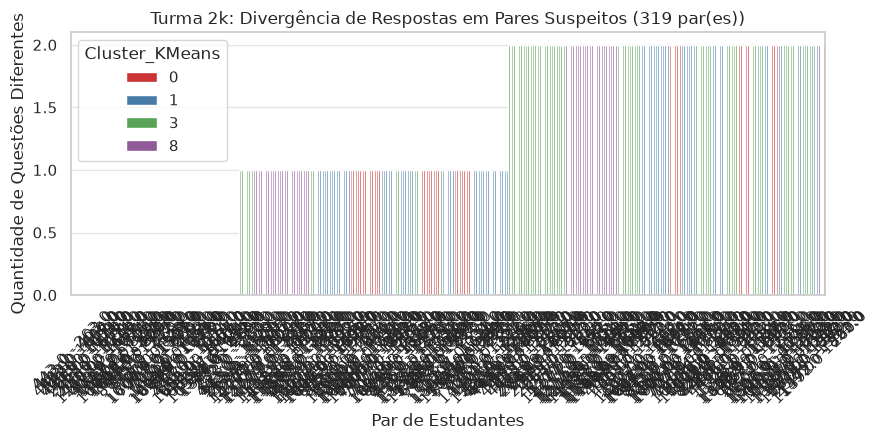

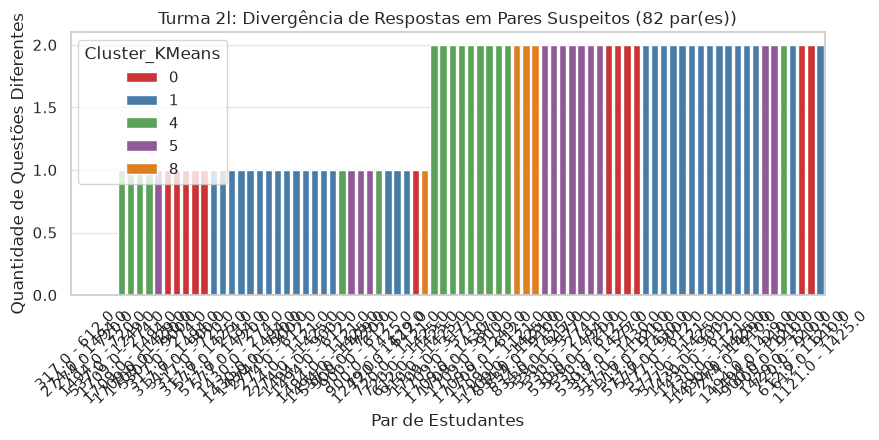

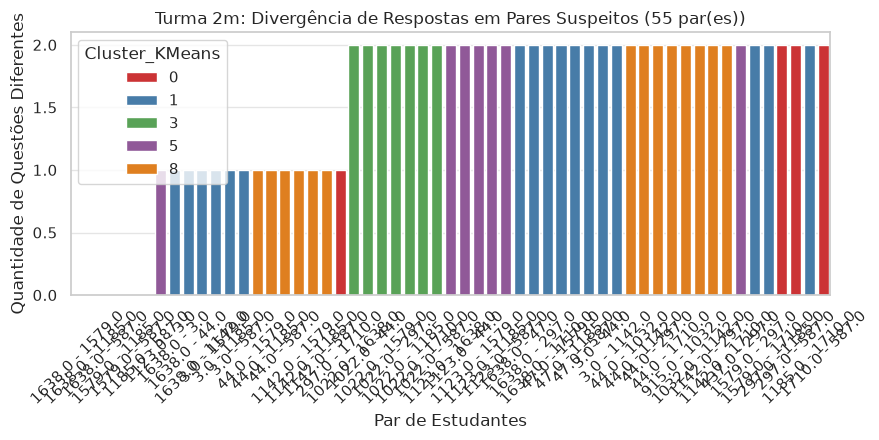

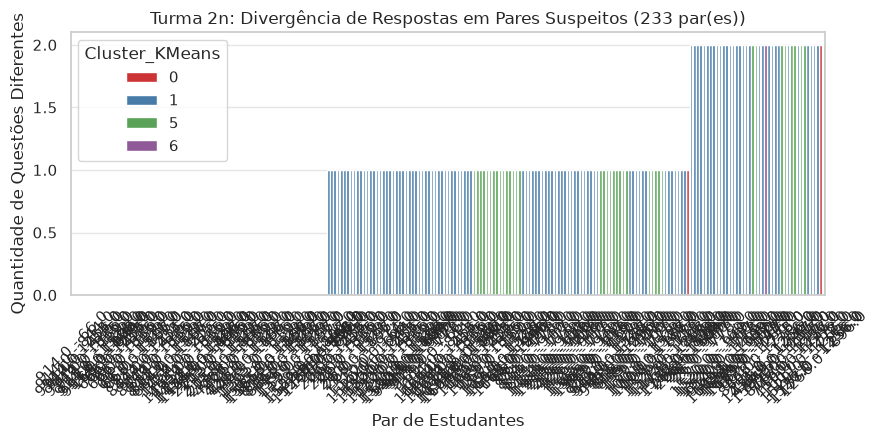

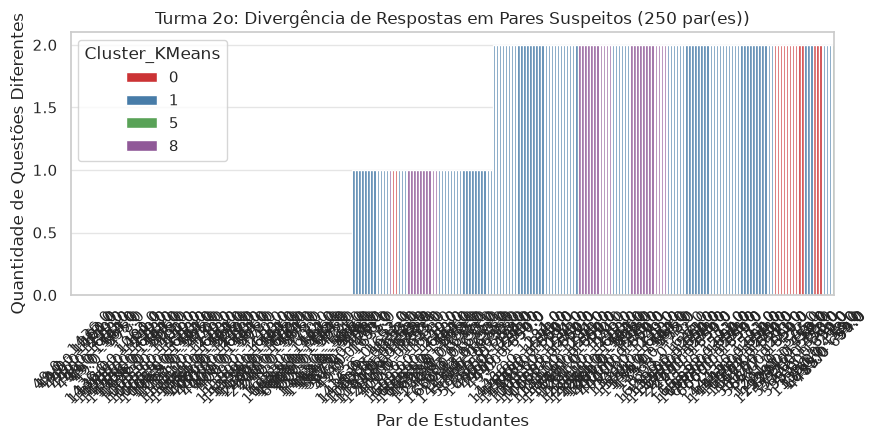

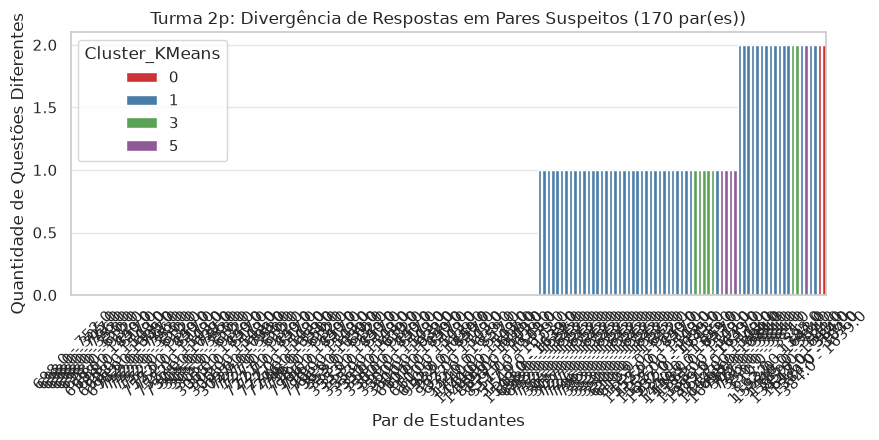

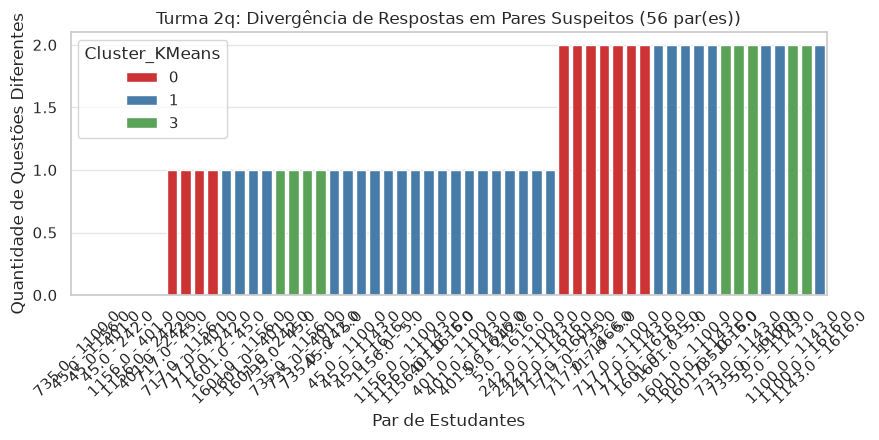

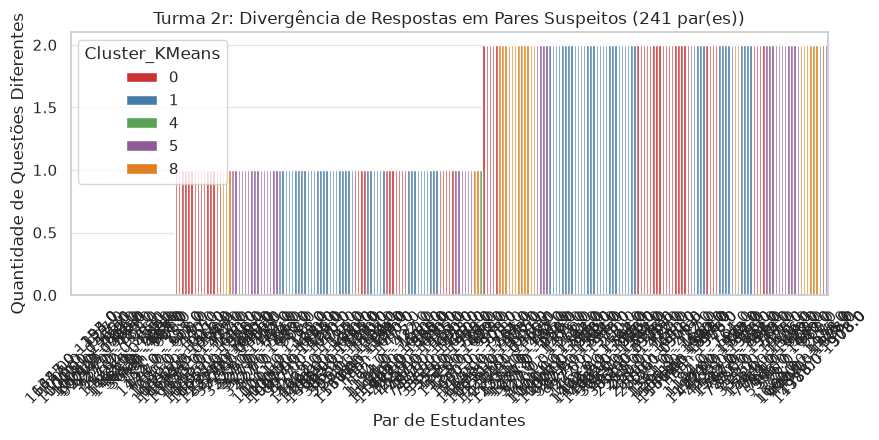

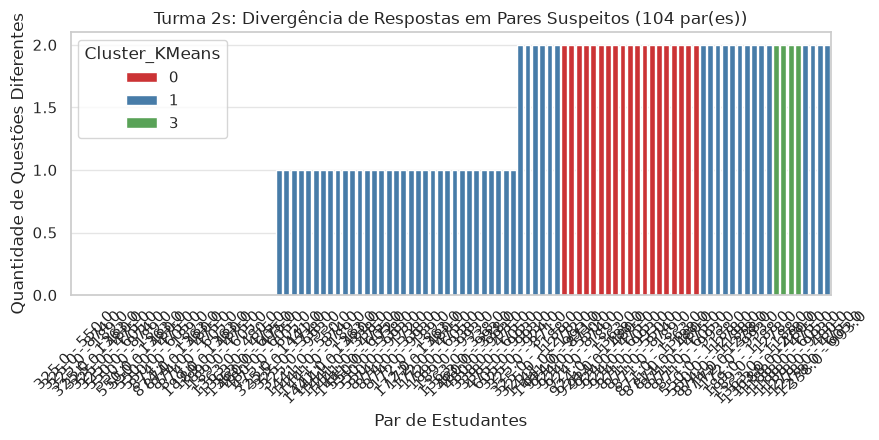

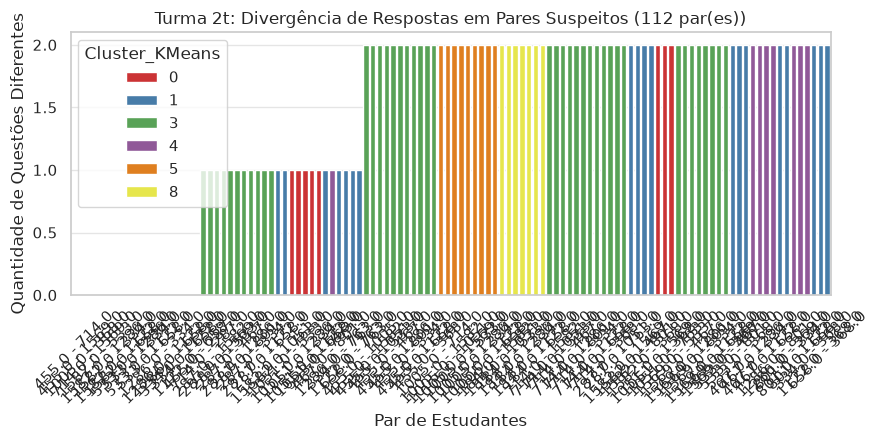

In [24]:
# ==============================================================================
# PIPELINE COMPLETO DE ANÁLISE DE RESPOSTAS E DETEÇÃO DE SUSPEITA DE COLA
# (APENAS PADRÃO DE RESPOSTAS / SEM ANÁLISE DE HORÁRIO / POR TURMA)
# ==============================================================================

import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import OneHotEncoder

# ------------------------------------------------------------------------------
# 1. Configuração do Ambiente e Carregamento dos Dados
# ------------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

# Tenta carregar o ficheiro de dados disponível
file_path = "data/prova_mat.csv"
try:
  df = pd.read_csv(file_path)
except FileNotFoundError:
  try:
    file_path = "prova_cn_2.csv"
    df = pd.read_csv(file_path)
  except FileNotFoundError:
    file_path = "prova_cn.csv"
    df = pd.read_csv(file_path)

print(f"--> Ficheiro carregado com sucesso: '{file_path}'")
print(f"--> Total de estudantes registados: {df.shape[0]}\n")

# ------------------------------------------------------------------------------
# 2. Pré-processamento e Codificação One-Hot Encoding
# ------------------------------------------------------------------------------
# Seleção das colunas correspondentes às questões (0 a 28)
question_cols = [str(i) for i in range(29) if str(i) in df.columns]

# Matriz de respostas tratadas
answers_df = df[question_cols].fillna(-1).astype(int)

# Representação das alternativas por One-Hot Encoding
encoder = OneHotEncoder(sparse_output=False)
X_ohe = encoder.fit_transform(answers_df)

print(f"Dimensão original das respostas: {answers_df.shape}")
print(f"Dimensão após One-Hot Encoding: {X_ohe.shape}\n")

# ------------------------------------------------------------------------------
# 3. Agrupamento K-Means e Seleção de K via Silhouette Score
# ------------------------------------------------------------------------------
silhouette_scores = []
k_range = list(range(2, 11))

for k in k_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = kmeans.fit_predict(X_ohe)
  score = silhouette_score(X_ohe, labels)
  silhouette_scores.append(score)

# Identificação do K com maior Silhouette Score
best_k_idx = np.argmax(silhouette_scores)
best_k = k_range[best_k_idx]

# Lógica de exibição do gráfico da Silhueta:
# - Se o melhor K for o primeiro (índice 0), exibe a partir dele e os posteriores.
# - Se for intermediário, exibe valores anteriores, o melhor K e os posteriores.
if best_k_idx == 0:
  plot_k = k_range
  plot_scores = silhouette_scores
  print(
      f"O melhor K ({best_k}) é o primeiro valor avaliado. Exibindo K={best_k} e"
      " valores posteriores."
  )
else:
  plot_k = k_range
  plot_scores = silhouette_scores
  print(
      f"O melhor K ({best_k}) é intermediário. Exibindo valores anteriores,"
      f" K={best_k} e posteriores."
  )

# Gráfico da curva do Silhouette Score
plt.figure(figsize=(8, 4))
plt.plot(plot_k, plot_scores, marker="o", color="navy", linewidth=2)
plt.axvline(
    x=best_k,
    color="red",
    linestyle="--",
    label=(
        f"Melhor K = {best_k} (Silhouette:"
        f" {silhouette_scores[best_k_idx]:.3f})"
    ),
)
plt.title("Escolha do K no K-Means via Silhouette Score")
plt.xlabel("Número de Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(plot_k)
plt.legend()
plt.tight_layout()
plt.show()

# Aplicação do K-Means definitivo
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["cluster_kmeans"] = kmeans_final.fit_predict(X_ohe)

print(f"Clusters atribuídos aos estudantes com K = {best_k}.\n")

# ------------------------------------------------------------------------------
# 4. Cálculo da Distância de Hamming (Divergência de Respostas)
# ------------------------------------------------------------------------------
num_questoes = len(question_cols)

# Matriz de distância de Hamming normalizada [0.0 a 1.0]
hamming_norm_matrix = squareform(pdist(answers_df.values, metric="hamming"))

# Conversão para contagem absoluta de questões divergentes entre pares
hamming_count_matrix = np.round(hamming_norm_matrix * num_questoes).astype(int)

# ------------------------------------------------------------------------------
# 5. Identificação dos Pares Suspeitos de Cola (Apenas Mesma Turma)
# ------------------------------------------------------------------------------
n_estudantes = len(df)
pares_suspeitos = []

# Limiar de alerta: até 2 questões divergentes no gabarito
MAX_DIVERGENCIA_QUESTOES = 2

for i in range(n_estudantes):
  for j in range(i + 1, n_estudantes):
    # FILTRO ESTRITO: Compara apenas estudantes da MESMA TURMA
    mesma_turma = (
        (df.loc[i, "serie_turma"] == df.loc[j, "serie_turma"])
        if "serie_turma" in df.columns
        else True
    )
    if not mesma_turma:
      continue

    q_diff = hamming_count_matrix[i, j]
    mesmo_cluster = (
        df.loc[i, "cluster_kmeans"] == df.loc[j, "cluster_kmeans"]
    )

    if q_diff <= MAX_DIVERGENCIA_QUESTOES:
      pares_suspeitos.append({
          "Estudante_1": df.loc[i, "estudante"],
          "Estudante_2": df.loc[j, "estudante"],
          "Par_Estudantes": (
              f"{df.loc[i, 'estudante']} - {df.loc[j, 'estudante']}"
          ),
          "Turma": (
              df.loc[i, "serie_turma"] if "serie_turma" in df.columns else "N/A"
          ),
          "Cluster_KMeans": df.loc[i, "cluster_kmeans"],
          "Questoes_Divergentes": q_diff,
          "Pontuacao_1": (
              df.loc[i, "pontuacao"] if "pontuacao" in df.columns else "N/A"
          ),
          "Pontuacao_2": (
              df.loc[j, "pontuacao"] if "pontuacao" in df.columns else "N/A"
          ),
      })

df_suspeitos = pd.DataFrame(pares_suspeitos)

if not df_suspeitos.empty:
  df_suspeitos = df_suspeitos.sort_values(
      by=["Turma", "Questoes_Divergentes"]
  )
  print("=========================================================")
  print(
      "  PARES DA MESMA TURMA COM INDÍCIOS SUSPEITOS DE COLA:"
      f" {len(df_suspeitos)}"
  )
  print("=========================================================\n")
  display(df_suspeitos)
else:
  print(
      "Nenhum par da mesma turma atendeu aos critérios de suspeita"
      " estabelecidos.\n"
  )

# ------------------------------------------------------------------------------
# 6. GERAÇÃO DE UM GRÁFICO INDIVIDUAL POR TURMA
# ------------------------------------------------------------------------------
turmas_unicas = (
    sorted(df["serie_turma"].unique())
    if "serie_turma" in df.columns
    else ["N/A"]
)

print("--> A gerar gráficos individuais de divergência por turma...")

for turma in turmas_unicas:
  plt.figure(figsize=(9, 4.5))

  # Filtra os pares suspeitos pertencentes à turma atual
  df_turma = (
      df_suspeitos[df_suspeitos["Turma"] == turma]
      if not df_suspeitos.empty
      else pd.DataFrame()
  )

  if not df_turma.empty:
    sns.barplot(
        data=df_turma,
        x="Par_Estudantes",
        y="Questoes_Divergentes",
        hue="Cluster_KMeans",
        palette="Set1",
    )
    plt.title(
        f"Turma {turma}: Divergência de Respostas em Pares Suspeitos"
        f" ({len(df_turma)} par(es))"
    )
    plt.xlabel("Par de Estudantes")
    plt.ylabel("Quantidade de Questões Diferentes")
    plt.xticks(rotation=45)
  else:
    # Mensagem caso a turma não apresente pares suspeitos
    plt.text(
        0.5,
        0.5,
        f"Nenhum par suspeito identificado na Turma {turma}",
        horizontalalignment="center",
        verticalalignment="center",
        transform=plt.gca().transAxes,
        fontsize=12,
        color="gray",
    )
    plt.title(f"Turma {turma}: Sem Suspeitas Detectadas")
    plt.xlabel("Par de Estudantes")
    plt.ylabel("Quantidade de Questões Diferentes")

  plt.tight_layout()
  plt.show()

--> Ficheiro carregado com sucesso: 'data/prova_mat.csv'
--> Total de estudantes registados: 274

Dimensão original das respostas: (274, 15)
Dimensão após One-Hot Encoding: (274, 72)

O melhor K (10) é intermediário. Exibindo valores anteriores, K=10 e posteriores.


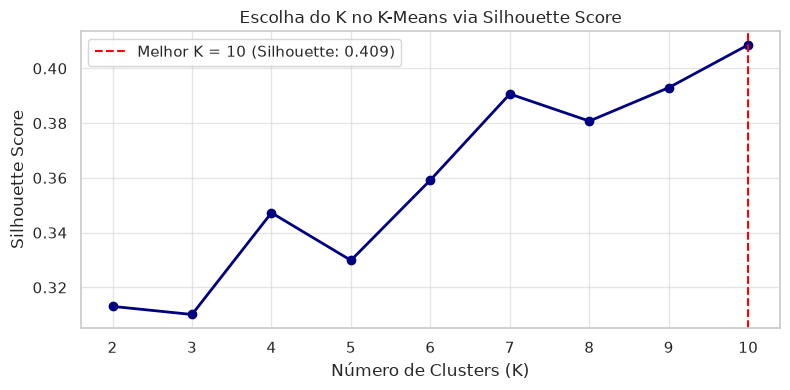

Clusters atribuídos aos estudantes com K = 10.

  PARES DA MESMA TURMA COM INDÍCIOS SUSPEITOS DE COLA: 1992



,Estudante_1,Estudante_2,Par_Estudantes,Turma,Cluster_KMeans,Questoes_Divergentes,Pontuacao_1,Pontuacao_2
10,370.0,1446.0,370.0 - 1446.0,2i,0,0,2400,2400
17,1382.0,201.0,1382.0 - 201.0,2i,0,0,2600,2600
21,1382.0,591.0,1382.0 - 591.0,2i,0,0,2600,2600
36,344.0,321.0,344.0 - 321.0,2i,1,0,2800,2800
37,344.0,1010.0,344.0 - 1010.0,2i,1,0,2800,2800
...,...,...,...,...,...,...,...,...
1981,801.0,1122.0,801.0 - 1122.0,2t,4,2,2400,2800
1982,801.0,658.0,801.0 - 658.0,2t,4,2,2400,2800
1985,334.0,368.0,334.0 - 368.0,2t,1,2,2800,2400
1988,1122.0,368.0,1122.0 - 368.0,2t,1,2,2800,2400


--> A gerar gráficos de barras de distribuição por cluster para cada turma...


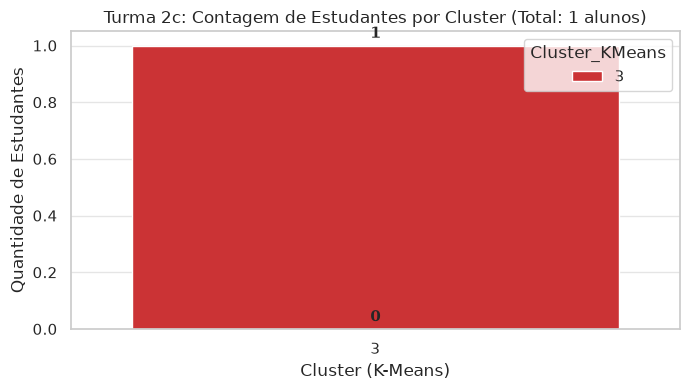

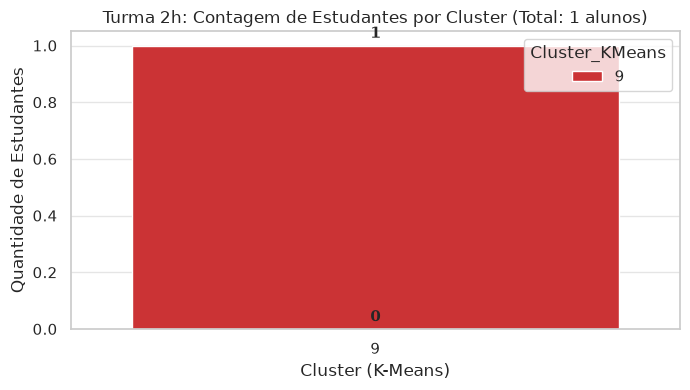

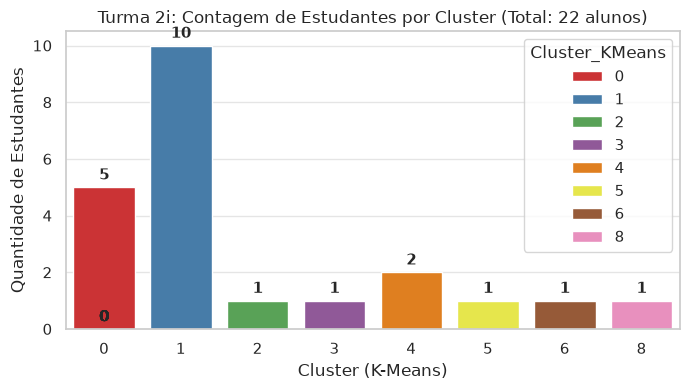

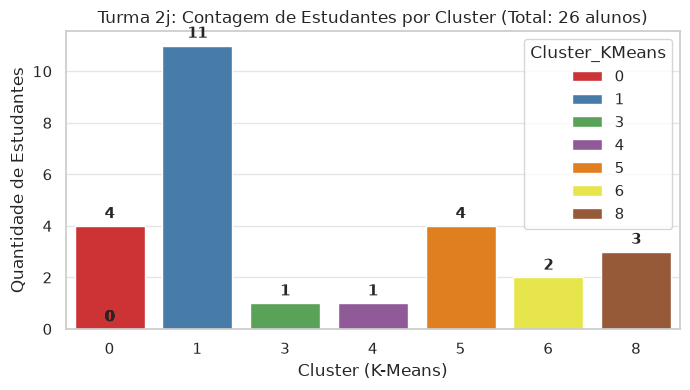

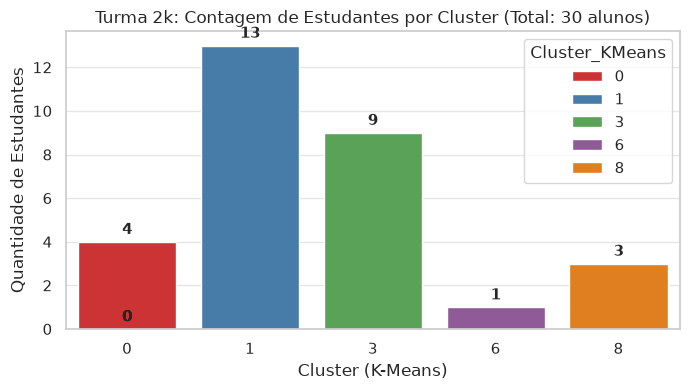

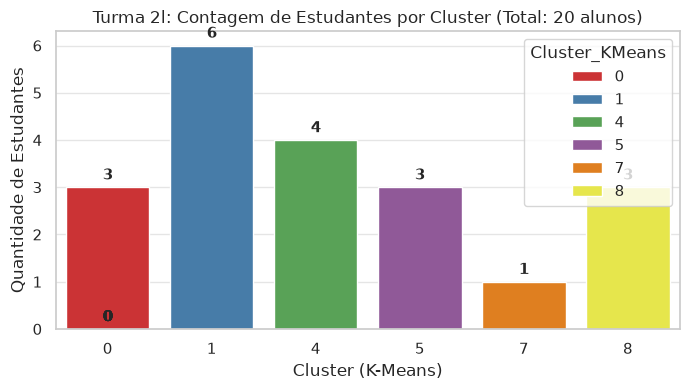

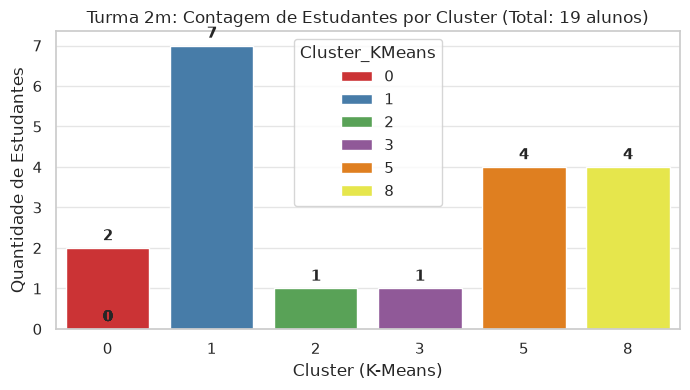

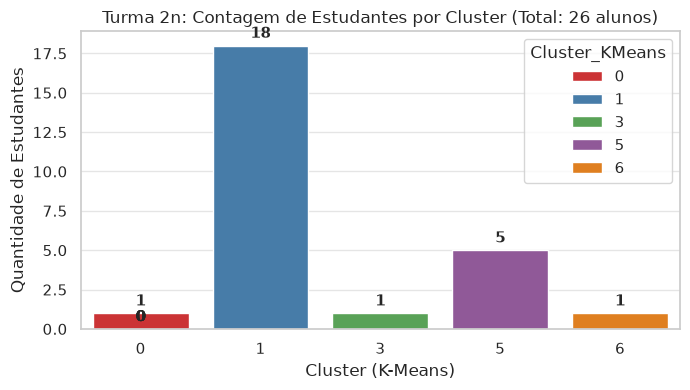

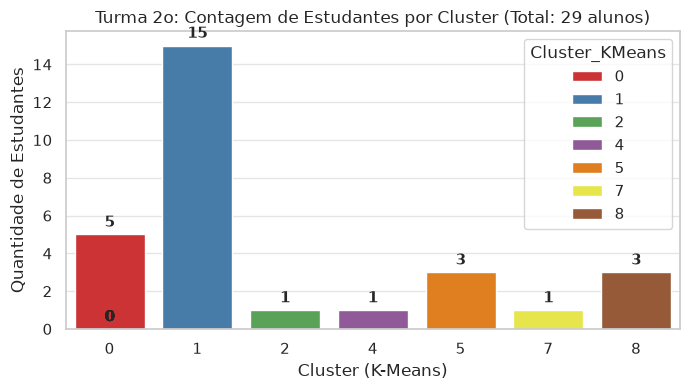

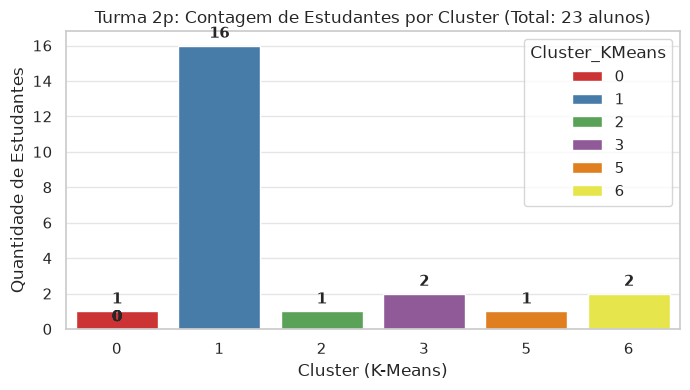

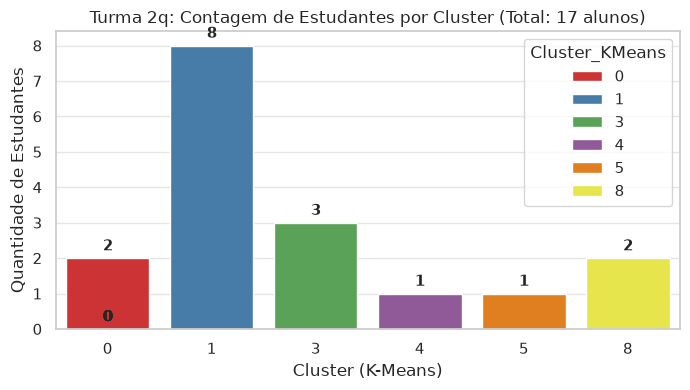

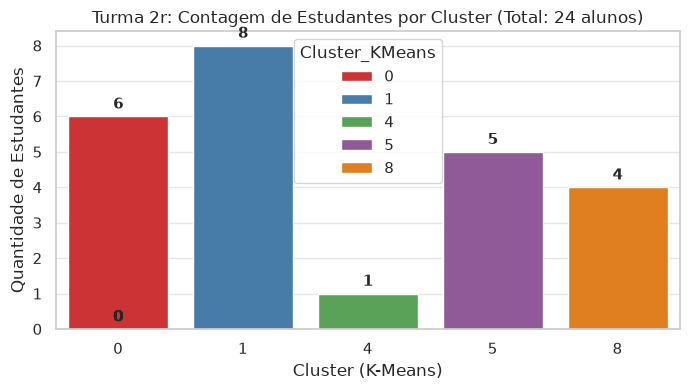

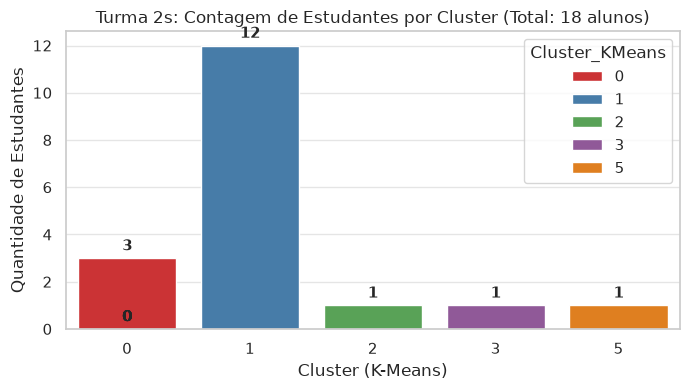

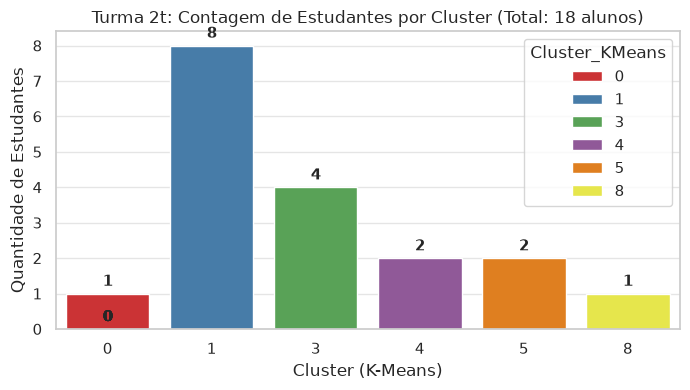

In [26]:
# ==============================================================================
# PIPELINE COMPLETO DE ANÁLISE DE RESPOSTAS E DETEÇÃO DE SUSPEITA DE COLA
# (CONTABILIDADE DE CLUSTERS POR TURMA EM GRÁFICO DE BARRAS)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform

# ------------------------------------------------------------------------------
# 1. Configuração do Ambiente e Carregamento dos Dados
# ------------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

# Tenta carregar o ficheiro de dados disponível
file_path = 'data/prova_mat.csv'
try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    try:
        file_path = 'prova_cn_2.csv'
        df = pd.read_csv(file_path)
    except FileNotFoundError:
        file_path = 'prova_cn.csv'
        df = pd.read_csv(file_path)

print(f"--> Ficheiro carregado com sucesso: '{file_path}'")
print(f"--> Total de estudantes registados: {df.shape[0]}\n")

# ------------------------------------------------------------------------------
# 2. Pré-processamento e Codificação One-Hot Encoding
# ------------------------------------------------------------------------------
# Seleção das colunas correspondentes às questões (0 a 28)
question_cols = [str(i) for i in range(29) if str(i) in df.columns]

# Matriz de respostas tratadas
answers_df = df[question_cols].fillna(-1).astype(int)

# Representação das alternativas por One-Hot Encoding
encoder = OneHotEncoder(sparse_output=False)
X_ohe = encoder.fit_transform(answers_df)

print(f"Dimensão original das respostas: {answers_df.shape}")
print(f"Dimensão após One-Hot Encoding: {X_ohe.shape}\n")

# ------------------------------------------------------------------------------
# 3. Agrupamento K-Means e Seleção de K via Silhouette Score
# ------------------------------------------------------------------------------
silhouette_scores = []
k_range = list(range(2, 11))

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_ohe)
    score = silhouette_score(X_ohe, labels)
    silhouette_scores.append(score)

# Identificação do K com maior Silhouette Score
best_k_idx = np.argmax(silhouette_scores)
best_k = k_range[best_k_idx]

# Lógica de exibição do gráfico da Silhueta
if best_k_idx == 0:
    plot_k = k_range
    plot_scores = silhouette_scores
    print(f"O melhor K ({best_k}) é o primeiro valor avaliado. Exibindo K={best_k} e valores posteriores.")
else:
    plot_k = k_range
    plot_scores = silhouette_scores
    print(f"O melhor K ({best_k}) é intermediário. Exibindo valores anteriores, K={best_k} e posteriores.")

# Gráfico da curva do Silhouette Score
plt.figure(figsize=(8, 4))
plt.plot(plot_k, plot_scores, marker='o', color='navy', linewidth=2)
plt.axvline(x=best_k, color='red', linestyle='--', label=f'Melhor K = {best_k} (Silhouette: {silhouette_scores[best_k_idx]:.3f})')
plt.title('Escolha do K no K-Means via Silhouette Score')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(plot_k)
plt.legend()
plt.tight_layout()
plt.show()

# Aplicação do K-Means definitivo
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans_final.fit_predict(X_ohe)

print(f"Clusters atribuídos aos estudantes com K = {best_k}.\n")

# ------------------------------------------------------------------------------
# 4. Cálculo da Distância de Hamming (Divergência de Respostas)
# ------------------------------------------------------------------------------
num_questoes = len(question_cols)

# Matriz de distância de Hamming normalizada [0.0 a 1.0]
hamming_norm_matrix = squareform(pdist(answers_df.values, metric='hamming'))

# Conversão para contagem absoluta de questões divergentes entre pares
hamming_count_matrix = np.round(hamming_norm_matrix * num_questoes).astype(int)

# ------------------------------------------------------------------------------
# 5. Identificação dos Pares Suspeitos de Cola (Apenas Mesma Turma)
# ------------------------------------------------------------------------------
n_estudantes = len(df)
pares_suspeitos = []

# Limiar de alerta: até 2 questões divergentes no gabarito
MAX_DIVERGENCIA_QUESTOES = 2

for i in range(n_estudantes):
    for j in range(i + 1, n_estudantes):
        # FILTRO ESTRITO: Compara apenas estudantes da MESMA TURMA
        mesma_turma = (df.loc[i, 'serie_turma'] == df.loc[j, 'serie_turma']) if 'serie_turma' in df.columns else True
        if not mesma_turma:
            continue

        q_diff = hamming_count_matrix[i, j]

        if q_diff <= MAX_DIVERGENCIA_QUESTOES:
            pares_suspeitos.append({
                'Estudante_1': df.loc[i, 'estudante'],
                'Estudante_2': df.loc[j, 'estudante'],
                'Par_Estudantes': f"{df.loc[i, 'estudante']} - {df.loc[j, 'estudante']}",
                'Turma': df.loc[i, 'serie_turma'] if 'serie_turma' in df.columns else 'N/A',
                'Cluster_KMeans': df.loc[i, 'cluster_kmeans'],
                'Questoes_Divergentes': q_diff,
                'Pontuacao_1': df.loc[i, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A',
                'Pontuacao_2': df.loc[j, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A'
            })

df_suspeitos = pd.DataFrame(pares_suspeitos)

if not df_suspeitos.empty:
    df_suspeitos = df_suspeitos.sort_values(by=['Turma', 'Questoes_Divergentes'])
    print("=========================================================")
    print(f"  PARES DA MESMA TURMA COM INDÍCIOS SUSPEITOS DE COLA: {len(df_suspeitos)}")
    print("=========================================================\n")
    display(df_suspeitos)
else:
    print("Nenhum par da mesma turma atendeu aos critérios de suspeita estabelecidos.\n")

# ------------------------------------------------------------------------------
# 6. GERAÇÃO DE GRÁFICOS DE BARRAS DA CONTABILIDADE DE CLUSTERS POR TURMA
# ------------------------------------------------------------------------------
turmas_unicas = sorted(df['serie_turma'].unique()) if 'serie_turma' in df.columns else ['N/A']

print("--> A gerar gráficos de barras de distribuição por cluster para cada turma...")

for turma in turmas_unicas:
    plt.figure(figsize=(7, 4))

    # Seleciona os estudantes da turma
    df_turma = df[df['serie_turma'] == turma] if 'serie_turma' in df.columns else df

    # Contagem de estudantes em cada cluster
    cluster_counts = df_turma['cluster_kmeans'].value_counts().reset_index()
    cluster_counts.columns = ['Cluster_KMeans', 'Quantidade_Alunos']
    cluster_counts = cluster_counts.sort_values('Cluster_KMeans')

    # Gráfico de barras
    ax = sns.barplot(
        data=cluster_counts,
        x='Cluster_KMeans',
        hue='Cluster_KMeans',
        y='Quantidade_Alunos',
        palette='Set1'
    )

    plt.title(f'Turma {turma}: Contagem de Estudantes por Cluster (Total: {len(df_turma)} alunos)')
    plt.xlabel('Cluster (K-Means)')
    plt.ylabel('Quantidade de Estudantes')

    # Adiciona o rótulo numérico exato sobre cada barra
    for p in ax.patches:
        height = int(p.get_height()) if not np.isnan(p.get_height()) else 0
        ax.annotate(f'{height}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=11, fontweight='bold',
                    xytext=(0, 3), textcoords='offset points')

    plt.tight_layout()
    plt.show()

--> Ficheiro carregado com sucesso: 'data/prova_mat.csv'
--> Total de estudantes registados (turmas com > 1 aluno): 272

Dimensão original das respostas: (272, 15)
Dimensão após One-Hot Encoding: (272, 72)

O melhor K (10) é intermediário. Exibindo valores anteriores, K=10 e posteriores.


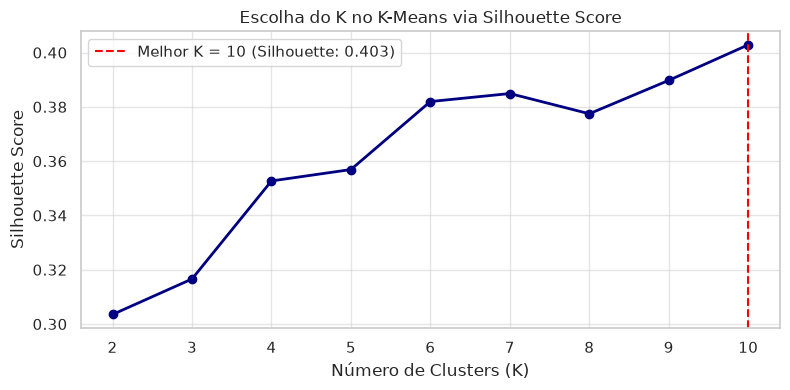

Clusters atribuídos aos estudantes com K = 10.

  PARES DA MESMA TURMA COM INDÍCIOS SUSPEITOS DE COLA: 1992



,Estudante_1,Estudante_2,Par_Estudantes,Turma,Cluster_KMeans,Questoes_Divergentes,Pontuacao_1,Pontuacao_2
10,370.0,1446.0,370.0 - 1446.0,2i,5,0,2400,2400
17,1382.0,201.0,1382.0 - 201.0,2i,3,0,2600,2600
21,1382.0,591.0,1382.0 - 591.0,2i,3,0,2600,2600
36,344.0,321.0,344.0 - 321.0,2i,0,0,2800,2800
37,344.0,1010.0,344.0 - 1010.0,2i,0,0,2800,2800
...,...,...,...,...,...,...,...,...
1981,801.0,1122.0,801.0 - 1122.0,2t,9,2,2400,2800
1982,801.0,658.0,801.0 - 658.0,2t,9,2,2400,2800
1985,334.0,368.0,334.0 - 368.0,2t,0,2,2800,2400
1988,1122.0,368.0,1122.0 - 368.0,2t,0,2,2800,2400


--> A gerar gráficos de barras de distribuição por cluster para cada turma validada (>1 aluno)...


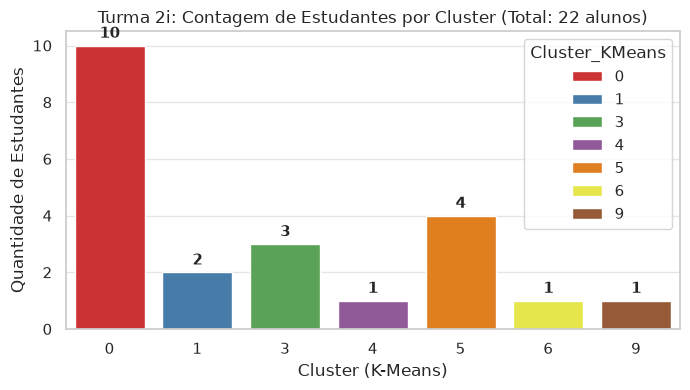

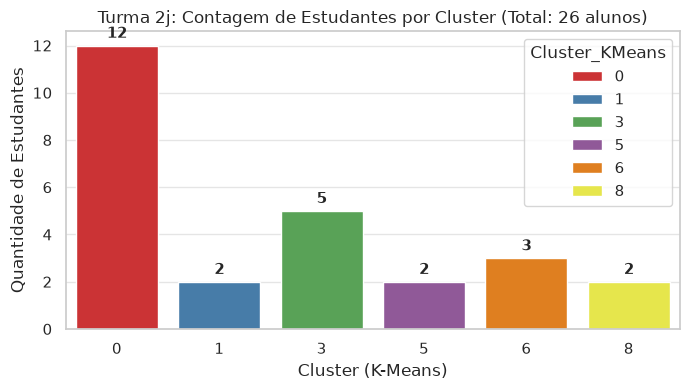

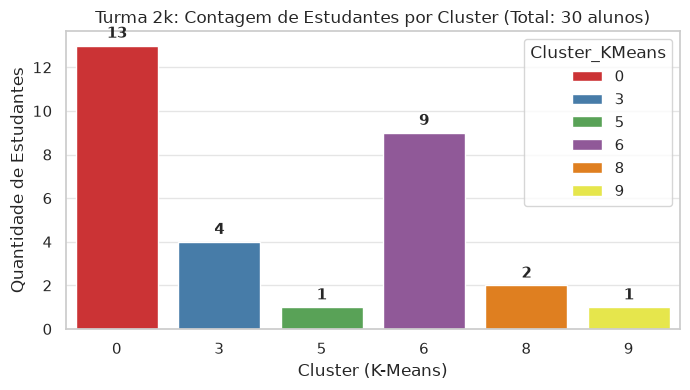

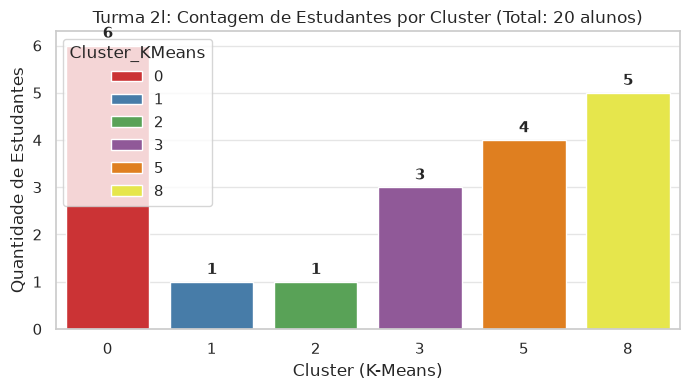

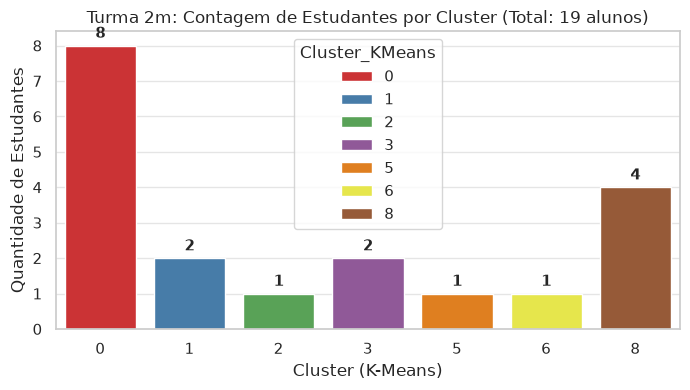

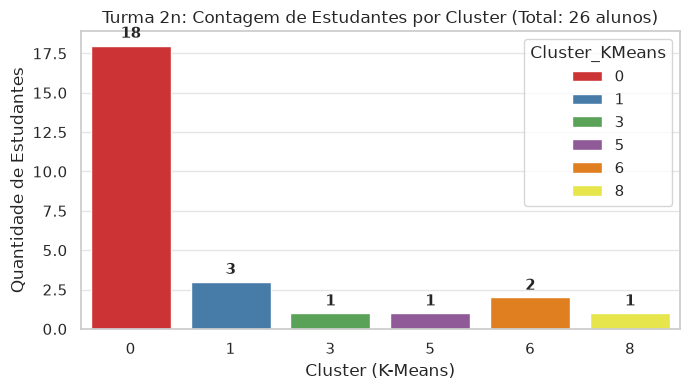

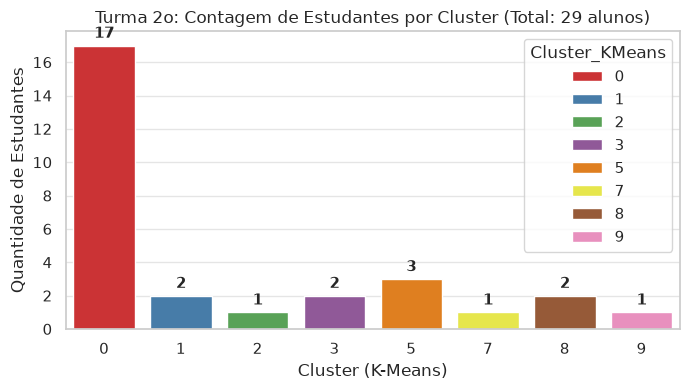

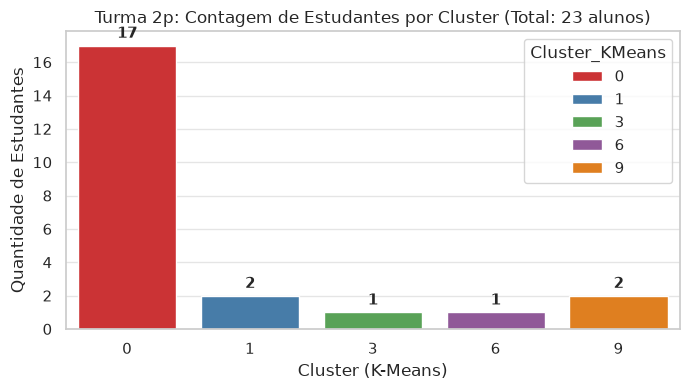

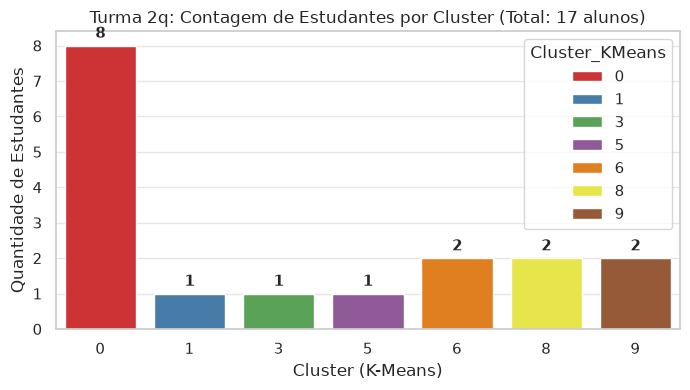

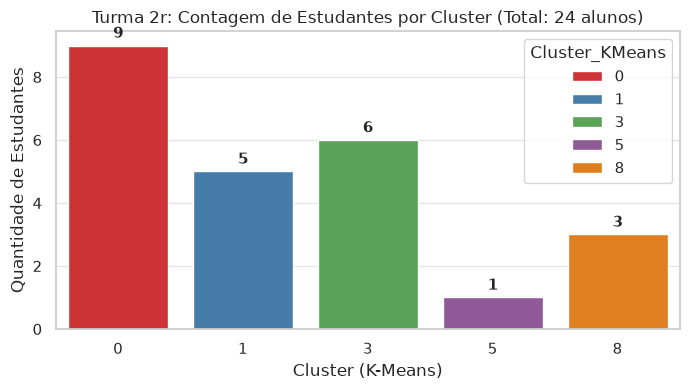

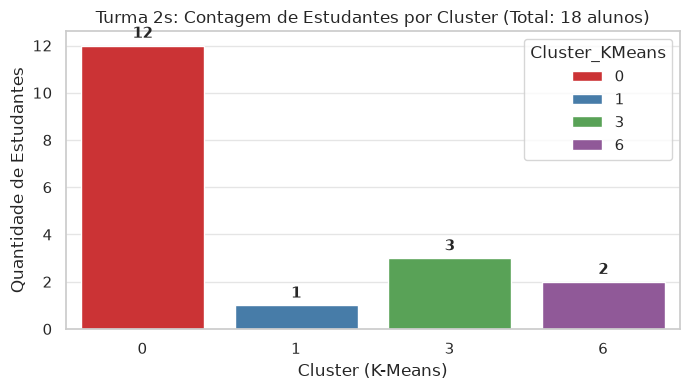

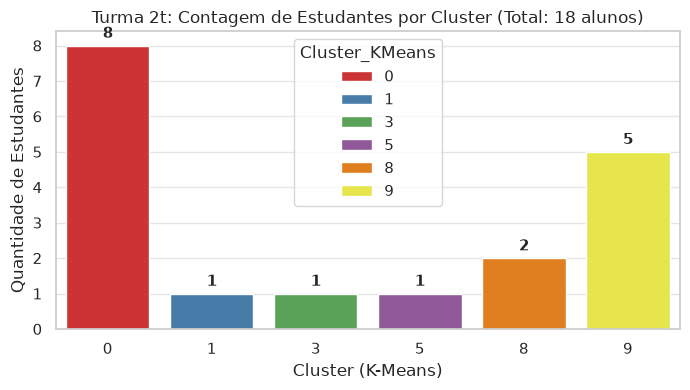

In [27]:
# ==============================================================================
# PIPELINE COMPLETO DE ANÁLISE DE RESPOSTAS E DETEÇÃO DE SUSPEITA DE COLA
# (CONTABILIDADE DE CLUSTERS POR TURMA - DESCONSIDERANDO TURMAS DE 1 ALUNO)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform

# ------------------------------------------------------------------------------
# 1. Configuração do Ambiente e Carregamento dos Dados
# ------------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

# Tenta carregar o ficheiro de dados disponível
file_path = 'data/prova_mat.csv'
try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    try:
        file_path = 'prova_cn_2.csv'
        df = pd.read_csv(file_path)
    except FileNotFoundError:
        file_path = 'prova_cn.csv'
        df = pd.read_csv(file_path)

# FILTRO: Desconsiderar turmas que possuem apenas 1 estudante
if 'serie_turma' in df.columns:
    contagem_alunos = df['serie_turma'].value_counts()
    turmas_validas = contagem_alunos[contagem_alunos > 1].index
    df = df[df['serie_turma'].isin(turmas_validas)].reset_index(drop=True)

print(f"--> Ficheiro carregado com sucesso: '{file_path}'")
print(f"--> Total de estudantes registados (turmas com > 1 aluno): {df.shape[0]}\n")

# ------------------------------------------------------------------------------
# 2. Pré-processamento e Codificação One-Hot Encoding
# ------------------------------------------------------------------------------
# Seleção das colunas correspondentes às questões (0 a 28)
question_cols = [str(i) for i in range(29) if str(i) in df.columns]

# Matriz de respostas tratadas
answers_df = df[question_cols].fillna(-1).astype(int)

# Representação das alternativas por One-Hot Encoding
encoder = OneHotEncoder(sparse_output=False)
X_ohe = encoder.fit_transform(answers_df)

print(f"Dimensão original das respostas: {answers_df.shape}")
print(f"Dimensão após One-Hot Encoding: {X_ohe.shape}\n")

# ------------------------------------------------------------------------------
# 3. Agrupamento K-Means e Seleção de K via Silhouette Score
# ------------------------------------------------------------------------------
silhouette_scores = []
k_range = list(range(2, 11))

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_ohe)
    score = silhouette_score(X_ohe, labels)
    silhouette_scores.append(score)

# Identificação do K com maior Silhouette Score
best_k_idx = np.argmax(silhouette_scores)
best_k = k_range[best_k_idx]

# Lógica para exibição do gráfico da Silhueta:
# - Se o melhor K for o primeiro (índice 0), exibe a partir dele e os posteriores.
# - Se for intermediário, exibe valores anteriores, o melhor K e os posteriores.
if best_k_idx == 0:
    plot_k = k_range
    plot_scores = silhouette_scores
    print(f"O melhor K ({best_k}) é o primeiro valor avaliado. Exibindo K={best_k} e valores posteriores.")
else:
    plot_k = k_range
    plot_scores = silhouette_scores
    print(f"O melhor K ({best_k}) é intermediário. Exibindo valores anteriores, K={best_k} e posteriores.")

# Gráfico da curva do Silhouette Score
plt.figure(figsize=(8, 4))
plt.plot(plot_k, plot_scores, marker='o', color='navy', linewidth=2)
plt.axvline(x=best_k, color='red', linestyle='--', label=f'Melhor K = {best_k} (Silhouette: {silhouette_scores[best_k_idx]:.3f})')
plt.title('Escolha do K no K-Means via Silhouette Score')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(plot_k)
plt.legend()
plt.tight_layout()
plt.show()

# Aplicação do K-Means definitivo
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans_final.fit_predict(X_ohe)

print(f"Clusters atribuídos aos estudantes com K = {best_k}.\n")

# ------------------------------------------------------------------------------
# 4. Cálculo da Distância de Hamming (Divergência de Respostas)
# ------------------------------------------------------------------------------
num_questoes = len(question_cols)

# Matriz de distância de Hamming normalizada [0.0 a 1.0]
hamming_norm_matrix = squareform(pdist(answers_df.values, metric='hamming'))

# Conversão para contagem absoluta de questões divergentes entre pares
hamming_count_matrix = np.round(hamming_norm_matrix * num_questoes).astype(int)

# ------------------------------------------------------------------------------
# 5. Identificação dos Pares Suspeitos de Cola (Apenas Mesma Turma)
# ------------------------------------------------------------------------------
n_estudantes = len(df)
pares_suspeitos = []

# Limiar de alerta: até 2 questões divergentes no gabarito
MAX_DIVERGENCIA_QUESTOES = 2

for i in range(n_estudantes):
    for j in range(i + 1, n_estudantes):
        # FILTRO ESTRITO: Compara apenas estudantes da MESMA TURMA
        mesma_turma = (df.loc[i, 'serie_turma'] == df.loc[j, 'serie_turma']) if 'serie_turma' in df.columns else True
        if not mesma_turma:
            continue

        q_diff = hamming_count_matrix[i, j]

        if q_diff <= MAX_DIVERGENCIA_QUESTOES:
            pares_suspeitos.append({
                'Estudante_1': df.loc[i, 'estudante'],
                'Estudante_2': df.loc[j, 'estudante'],
                'Par_Estudantes': f"{df.loc[i, 'estudante']} - {df.loc[j, 'estudante']}",
                'Turma': df.loc[i, 'serie_turma'] if 'serie_turma' in df.columns else 'N/A',
                'Cluster_KMeans': df.loc[i, 'cluster_kmeans'],
                'Questoes_Divergentes': q_diff,
                'Pontuacao_1': df.loc[i, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A',
                'Pontuacao_2': df.loc[j, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A'
            })

df_suspeitos = pd.DataFrame(pares_suspeitos)

if not df_suspeitos.empty:
    df_suspeitos = df_suspeitos.sort_values(by=['Turma', 'Questoes_Divergentes'])
    print("=========================================================")
    print(f"  PARES DA MESMA TURMA COM INDÍCIOS SUSPEITOS DE COLA: {len(df_suspeitos)}")
    print("=========================================================\n")
    display(df_suspeitos)
else:
    print("Nenhum par da mesma turma atendeu aos critérios de suspeita estabelecidos.\n")

# ------------------------------------------------------------------------------
# 6. GERAÇÃO DE GRÁFICOS DE BARRAS DA CONTABILIDADE DE CLUSTERS POR TURMA
# ------------------------------------------------------------------------------
turmas_unicas = sorted(df['serie_turma'].unique()) if 'serie_turma' in df.columns else ['N/A']

print("--> A gerar gráficos de barras de distribuição por cluster para cada turma validada (>1 aluno)...")

for turma in turmas_unicas:
    # Seleciona os estudantes da turma
    df_turma = df[df['serie_turma'] == turma] if 'serie_turma' in df.columns else df

    # Ignora turmas com 1 ou menos alunos
    if len(df_turma) <= 1:
        continue

    plt.figure(figsize=(7, 4))

    # Contagem de estudantes em cada cluster
    cluster_counts = df_turma['cluster_kmeans'].value_counts().reset_index()
    cluster_counts.columns = ['Cluster_KMeans', 'Quantidade_Alunos']
    cluster_counts = cluster_counts.sort_values('Cluster_KMeans')

    # Gráfico de barras
    ax = sns.barplot(
        data=cluster_counts,
        x='Cluster_KMeans',
        hue='Cluster_KMeans',
        y='Quantidade_Alunos',
        palette='Set1'
    )

    plt.title(f'Turma {turma}: Contagem de Estudantes por Cluster (Total: {len(df_turma)} alunos)')
    plt.xlabel('Cluster (K-Means)')
    plt.ylabel('Quantidade de Estudantes')

    # Adiciona o rótulo numérico exato sobre cada barra
    for p in ax.patches:
        height = int(p.get_height()) if not np.isnan(p.get_height()) else 0
        if height > 0:
            ax.annotate(f'{height}',
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom',
                        fontsize=11, fontweight='bold',
                        xytext=(0, 3), textcoords='offset points')

    plt.tight_layout()
    plt.show()

--> Ficheiro carregado com sucesso: 'data/prova_mat.csv'
--> Total de estudantes registados (turmas com > 1 aluno): 272

Dimensão original das respostas: (272, 15)
Dimensão após One-Hot Encoding: (272, 72)

O melhor K (10) é intermediário. Exibindo valores anteriores, K=10 e posteriores.


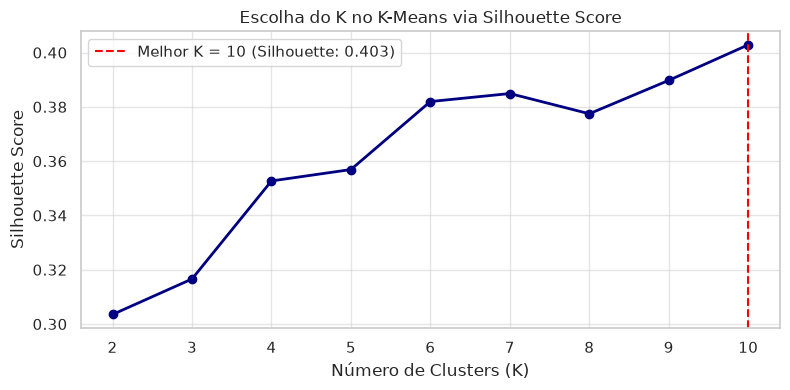

Clusters atribuídos aos estudantes com K = 10.

  PARES DO MESMO GRUPO/TURMA COM INDÍCIOS SUSPEITOS DE COLA: 881



,Estudante_1,Estudante_2,Par_Estudantes,Turma,Cluster_KMeans,Questoes_Divergentes,Pontuacao_1,Pontuacao_2
5,344.0,321.0,344.0 - 321.0,2i,0,0,2800,2800
6,344.0,1010.0,344.0 - 1010.0,2i,0,0,2800,2800
7,344.0,671.0,344.0 - 671.0,2i,0,0,2800,2800
8,344.0,1360.0,344.0 - 1360.0,2i,0,0,2800,2800
10,344.0,1144.0,344.0 - 1144.0,2i,0,0,2800,2800
...,...,...,...,...,...,...,...,...
857,287.0,1569.0,287.0 - 1569.0,2t,9,1,2600,2400
858,287.0,801.0,287.0 - 801.0,2t,9,1,2600,2400
852,455.0,801.0,455.0 - 801.0,2t,9,2,2400,2400
856,714.0,801.0,714.0 - 801.0,2t,9,2,2400,2400


--> A gerar gráficos de barras de distribuição por cluster para cada turma validada (>1 aluno)...


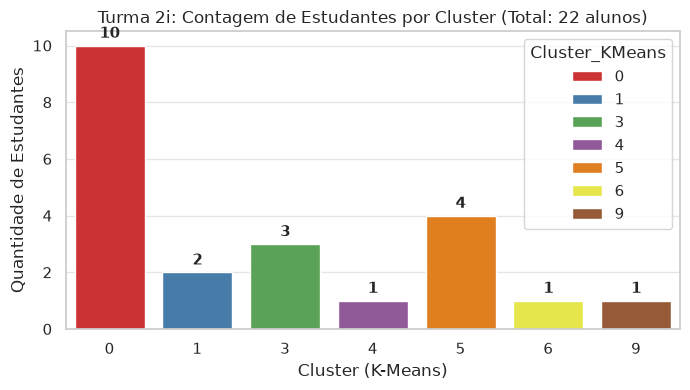

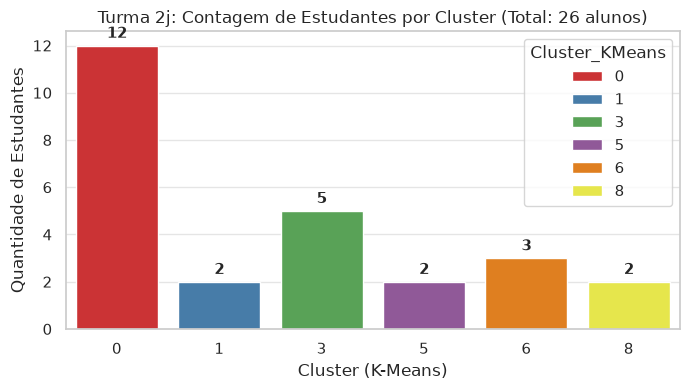

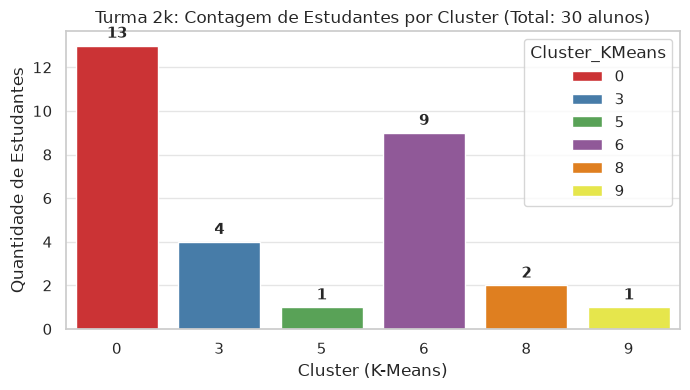

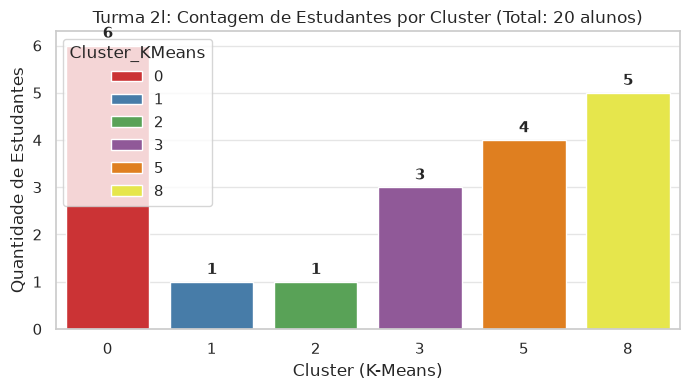

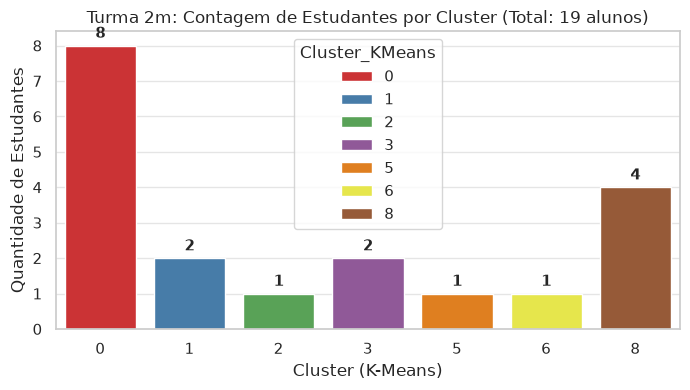

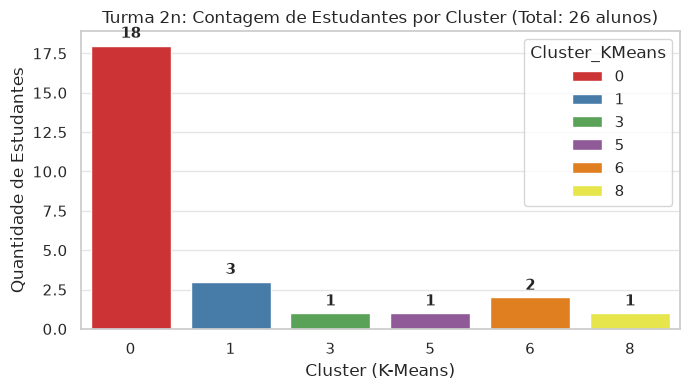

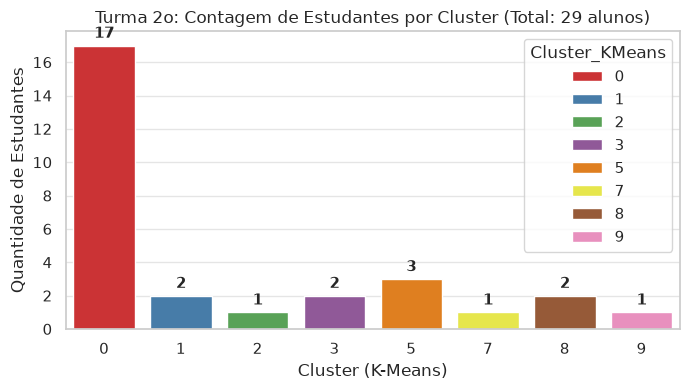

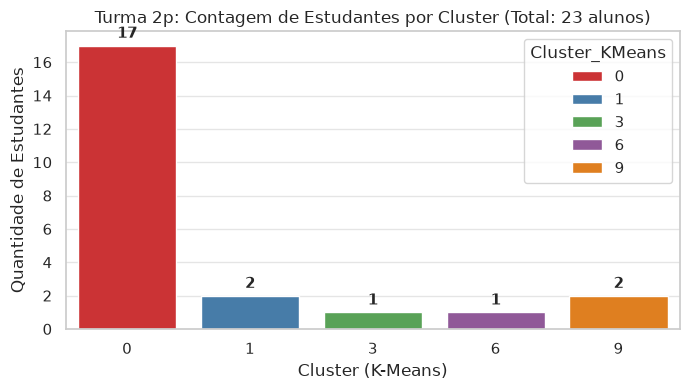

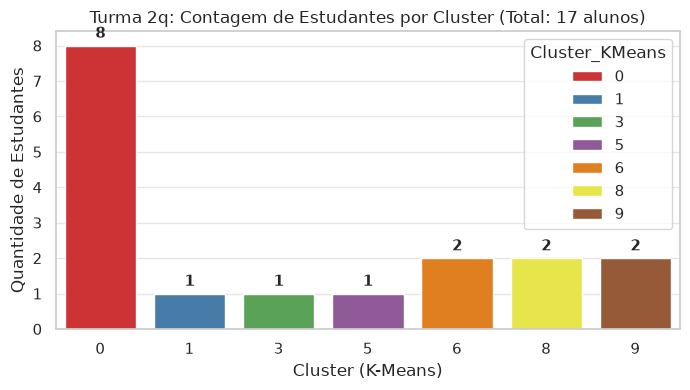

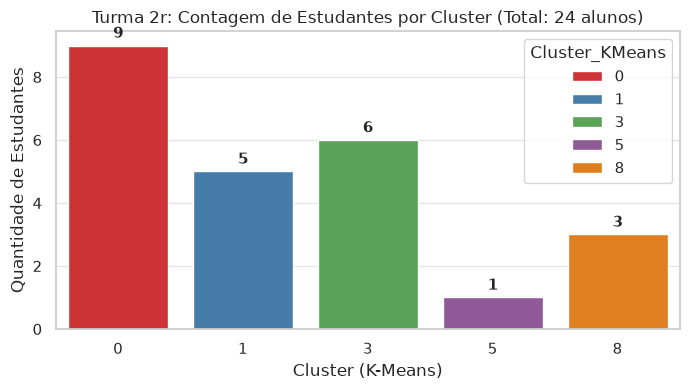

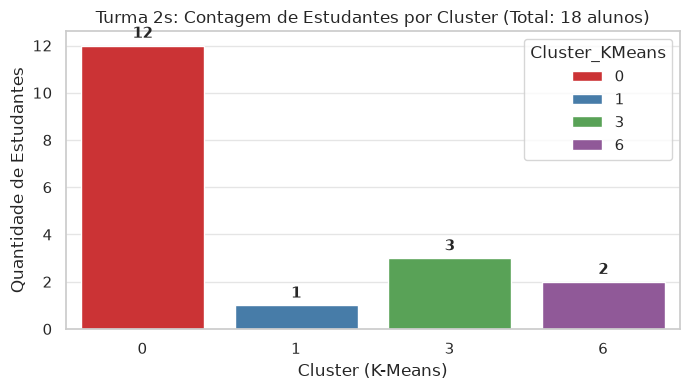

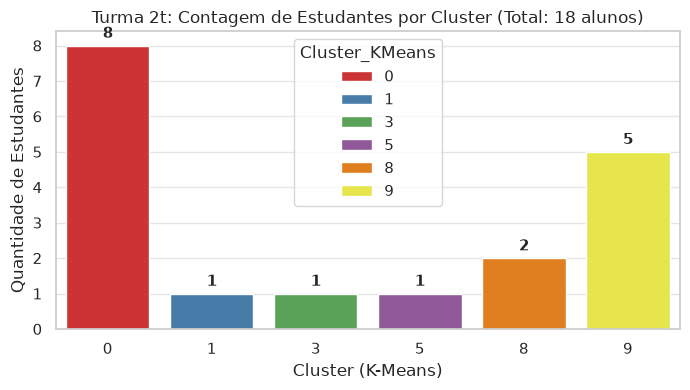

In [28]:
# ==============================================================================
# PIPELINE COMPLETO DE ANÁLISE DE RESPOSTAS E DETEÇÃO DE SUSPEITA DE COLA
# (DISTÂNCIA DE HAMMING RESTRITA A ESTUDANTES DO MESMO GRUPO/CLUSTER E TURMA)
# ==============================================================================

import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import OneHotEncoder

# ------------------------------------------------------------------------------
# 1. Configuração do Ambiente e Carregamento dos Dados
# ------------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

# Tenta carregar o ficheiro de dados disponível
file_path = "data/prova_mat.csv"
try:
  df = pd.read_csv(file_path)
except FileNotFoundError:
  try:
    file_path = "prova_cn_2.csv"
    df = pd.read_csv(file_path)
  except FileNotFoundError:
    file_path = "prova_cn.csv"
    df = pd.read_csv(file_path)

# FILTRO: Desconsiderar turmas que possuem apenas 1 estudante
if "serie_turma" in df.columns:
  contagem_alunos = df["serie_turma"].value_counts()
  turmas_validas = contagem_alunos[contagem_alunos > 1].index
  df = df[df["serie_turma"].isin(turmas_validas)].reset_index(drop=True)

print(f"--> Ficheiro carregado com sucesso: '{file_path}'")
print(
    "--> Total de estudantes registados (turmas com > 1 aluno):"
    f" {df.shape[0]}\n"
)

# ------------------------------------------------------------------------------
# 2. Pré-processamento e Codificação One-Hot Encoding
# ------------------------------------------------------------------------------
# Seleção das colunas correspondentes às questões (0 a 28)
question_cols = [str(i) for i in range(29) if str(i) in df.columns]

# Matriz de respostas tratadas
answers_df = df[question_cols].fillna(-1).astype(int)

# Representação das alternativas por One-Hot Encoding
encoder = OneHotEncoder(sparse_output=False)
X_ohe = encoder.fit_transform(answers_df)

print(f"Dimensão original das respostas: {answers_df.shape}")
print(f"Dimensão após One-Hot Encoding: {X_ohe.shape}\n")

# ------------------------------------------------------------------------------
# 3. Agrupamento K-Means e Seleção de K via Silhouette Score
# ------------------------------------------------------------------------------
silhouette_scores = []
k_range = list(range(2, 11))

for k in k_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = kmeans.fit_predict(X_ohe)
  score = silhouette_score(X_ohe, labels)
  silhouette_scores.append(score)

# Identificação do K com maior Silhouette Score
best_k_idx = np.argmax(silhouette_scores)
best_k = k_range[best_k_idx]

# Lógica para exibição do gráfico da Silhueta
if best_k_idx == 0:
  plot_k = k_range
  plot_scores = silhouette_scores
  print(
      f"O melhor K ({best_k}) é o primeiro valor avaliado. Exibindo K={best_k} e"
      " valores posteriores."
  )
else:
  plot_k = k_range
  plot_scores = silhouette_scores
  print(
      f"O melhor K ({best_k}) é intermediário. Exibindo valores anteriores,"
      f" K={best_k} e posteriores."
  )

# Gráfico da curva do Silhouette Score
plt.figure(figsize=(8, 4))
plt.plot(plot_k, plot_scores, marker="o", color="navy", linewidth=2)
plt.axvline(
    x=best_k,
    color="red",
    linestyle="--",
    label=(
        f"Melhor K = {best_k} (Silhouette:"
        f" {silhouette_scores[best_k_idx]:.3f})"
    ),
)
plt.title("Escolha do K no K-Means via Silhouette Score")
plt.xlabel("Número de Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(plot_k)
plt.legend()
plt.tight_layout()
plt.show()

# Aplicação do K-Means definitivo
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["cluster_kmeans"] = kmeans_final.fit_predict(X_ohe)

print(f"Clusters atribuídos aos estudantes com K = {best_k}.\n")

# ------------------------------------------------------------------------------
# 4. Cálculo da Distância de Hamming (Divergência de Respostas)
# ------------------------------------------------------------------------------
num_questoes = len(question_cols)

# Matriz de distância de Hamming normalizada [0.0 a 1.0]
hamming_norm_matrix = squareform(pdist(answers_df.values, metric="hamming"))

# Conversão para contagem absoluta de questões divergentes entre pares
hamming_count_matrix = np.round(hamming_norm_matrix * num_questoes).astype(int)

# ------------------------------------------------------------------------------
# 5. Identificação de Pares Suspeitos (RESTRITO AO MESMO GRUPO E MESMA TURMA)
# ------------------------------------------------------------------------------
n_estudantes = len(df)
pares_suspeitos = []

# Limiar de alerta: até 2 questões divergentes no gabarito
MAX_DIVERGENCIA_QUESTOES = 2

for i in range(n_estudantes):
  for j in range(i + 1, n_estudantes):
    # FILTRO ESTRITO: Compara APENAS estudantes do MESMO CLUSTER/GRUPO e da MESMA TURMA
    mesmo_cluster = (
        df.loc[i, "cluster_kmeans"] == df.loc[j, "cluster_kmeans"]
    )
    mesma_turma = (
        (df.loc[i, "serie_turma"] == df.loc[j, "serie_turma"])
        if "serie_turma" in df.columns
        else True
    )

    if not (mesmo_cluster and mesma_turma):
      continue

    q_diff = hamming_count_matrix[i, j]

    if q_diff <= MAX_DIVERGENCIA_QUESTOES:
      pares_suspeitos.append({
          "Estudante_1": df.loc[i, "estudante"],
          "Estudante_2": df.loc[j, "estudante"],
          "Par_Estudantes": (
              f"{df.loc[i, 'estudante']} - {df.loc[j, 'estudante']}"
          ),
          "Turma": (
              df.loc[i, "serie_turma"] if "serie_turma" in df.columns else "N/A"
          ),
          "Cluster_KMeans": df.loc[i, "cluster_kmeans"],
          "Questoes_Divergentes": q_diff,
          "Pontuacao_1": (
              df.loc[i, "pontuacao"] if "pontuacao" in df.columns else "N/A"
          ),
          "Pontuacao_2": (
              df.loc[j, "pontuacao"] if "pontuacao" in df.columns else "N/A"
          ),
      })

df_suspeitos = pd.DataFrame(pares_suspeitos)

if not df_suspeitos.empty:
  df_suspeitos = df_suspeitos.sort_values(
      by=["Turma", "Cluster_KMeans", "Questoes_Divergentes"]
  )
  print("=========================================================")
  print(
      "  PARES DO MESMO GRUPO/TURMA COM INDÍCIOS SUSPEITOS DE COLA:"
      f" {len(df_suspeitos)}"
  )
  print("=========================================================\n")
  display(df_suspeitos)
else:
  print(
      "Nenhum par do mesmo grupo/turma atendeu aos critérios de suspeita"
      " estabelecidos.\n"
  )

# ------------------------------------------------------------------------------
# 6. GERAÇÃO DE GRÁFICOS DE BARRAS DA CONTABILIDADE DE CLUSTERS POR TURMA
# ------------------------------------------------------------------------------
turmas_unicas = (
    sorted(df["serie_turma"].unique())
    if "serie_turma" in df.columns
    else ["N/A"]
)

print(
    "--> A gerar gráficos de barras de distribuição por cluster para cada"
    " turma validada (>1 aluno)..."
)

for turma in turmas_unicas:
  # Seleciona os estudantes da turma
  df_turma = df[df["serie_turma"] == turma] if "serie_turma" in df.columns else df

  # Ignora turmas com 1 ou menos alunos
  if len(df_turma) <= 1:
    continue

  plt.figure(figsize=(7, 4))

  # Contagem de estudantes em cada cluster
  cluster_counts = df_turma["cluster_kmeans"].value_counts().reset_index()
  cluster_counts.columns = ["Cluster_KMeans", "Quantidade_Alunos"]
  cluster_counts = cluster_counts.sort_values("Cluster_KMeans")

  # Gráfico de barras
  ax = sns.barplot(
      data=cluster_counts,
      x="Cluster_KMeans",
      hue="Cluster_KMeans",
      y="Quantidade_Alunos",
      palette="Set1",
  )

  plt.title(
      f"Turma {turma}: Contagem de Estudantes por Cluster (Total:"
      f" {len(df_turma)} alunos)"
  )
  plt.xlabel("Cluster (K-Means)")
  plt.ylabel("Quantidade de Estudantes")

  # Adiciona o rótulo numérico exato sobre cada barra
  for p in ax.patches:
    height = int(p.get_height()) if not np.isnan(p.get_height()) else 0
    if height > 0:
      ax.annotate(
          f"{height}",
          (p.get_x() + p.get_width() / 2.0, height),
          ha="center",
          va="bottom",
          fontsize=11,
          fontweight="bold",
          xytext=(0, 3),
          textcoords="offset points",
      )

  plt.tight_layout()
  plt.show()

--> Ficheiro carregado com sucesso: 'data/prova_mat.csv'
--> Total de estudantes registados (turmas com > 1 aluno): 272

Dimensão original das respostas: (272, 15)
Dimensão após One-Hot Encoding: (272, 72)

O melhor K (10) é intermediário. Exibindo valores anteriores, K=10 e posteriores.


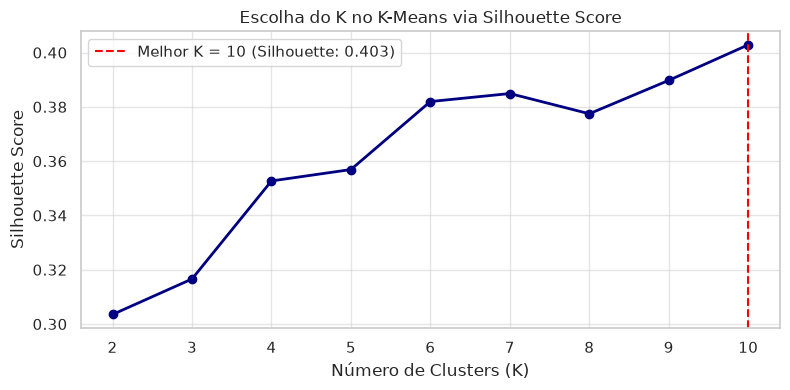

Clusters atribuídos aos estudantes com K = 10.

  PARES DO MESMO GRUPO/TURMA COM INDÍCIOS SUSPEITOS DE COLA: 881



,Estudante_1,Estudante_2,Par_Estudantes,Turma,Cluster_KMeans,Questoes_Divergentes,Nivel_Similaridade,Pontuacao_1,Pontuacao_2
5,344.0,321.0,344.0 - 321.0,2i,0,0,Muito Alta (0 divergências),2800,2800
6,344.0,1010.0,344.0 - 1010.0,2i,0,0,Muito Alta (0 divergências),2800,2800
7,344.0,671.0,344.0 - 671.0,2i,0,0,Muito Alta (0 divergências),2800,2800
8,344.0,1360.0,344.0 - 1360.0,2i,0,0,Muito Alta (0 divergências),2800,2800
10,344.0,1144.0,344.0 - 1144.0,2i,0,0,Muito Alta (0 divergências),2800,2800
...,...,...,...,...,...,...,...,...,...
857,287.0,1569.0,287.0 - 1569.0,2t,9,1,Alta (1 a 2 divergências),2600,2400
858,287.0,801.0,287.0 - 801.0,2t,9,1,Alta (1 a 2 divergências),2600,2400
852,455.0,801.0,455.0 - 801.0,2t,9,2,Alta (1 a 2 divergências),2400,2400
856,714.0,801.0,714.0 - 801.0,2t,9,2,Alta (1 a 2 divergências),2400,2400


--> A gerar gráficos de barras de distribuição por cluster para cada turma validada (>1 aluno)...


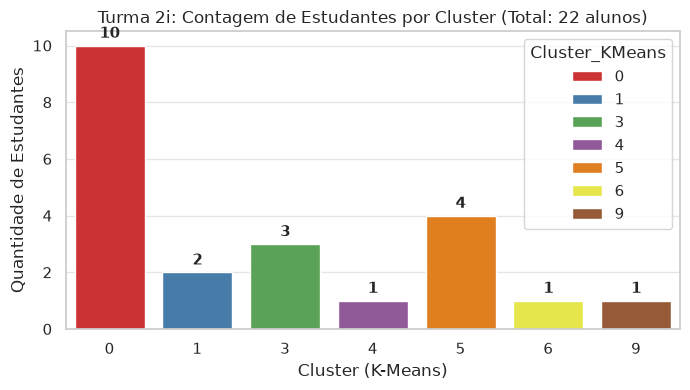

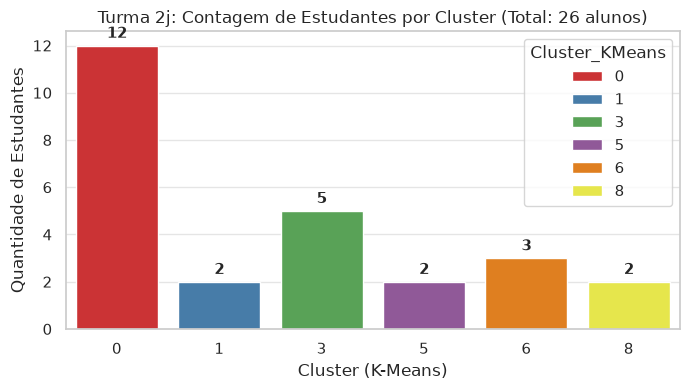

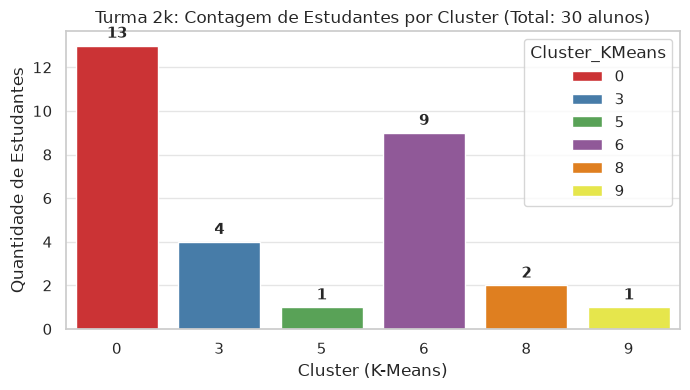

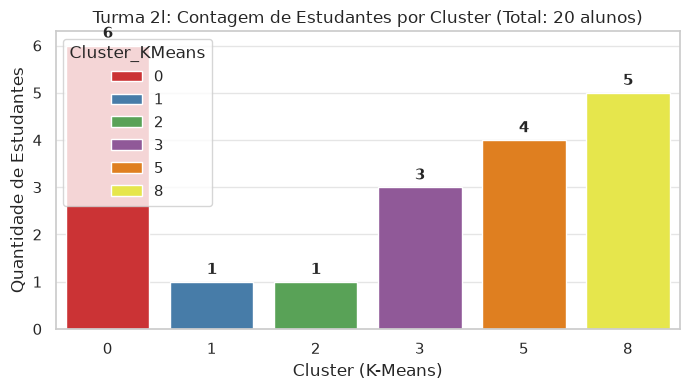

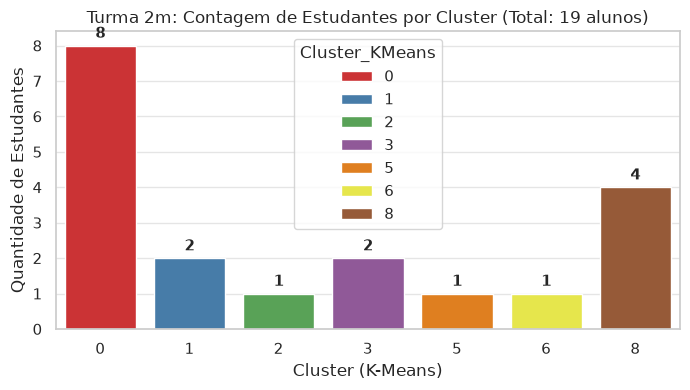

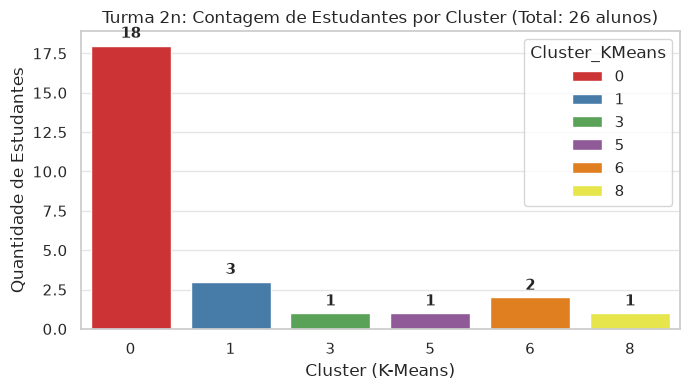

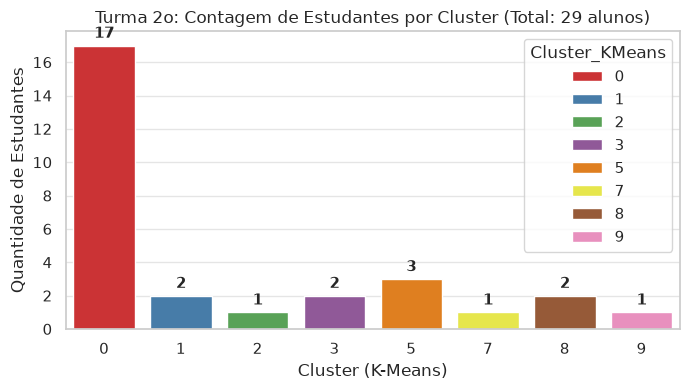

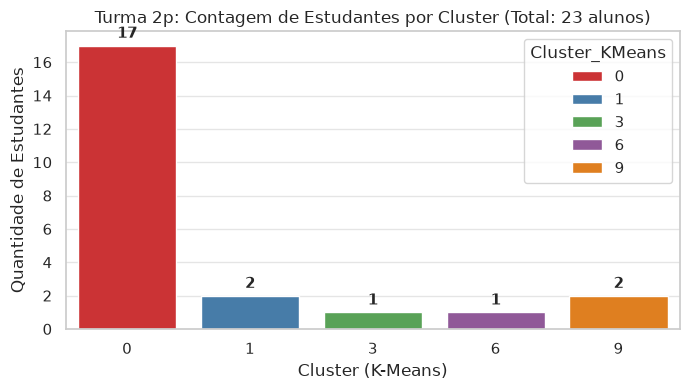

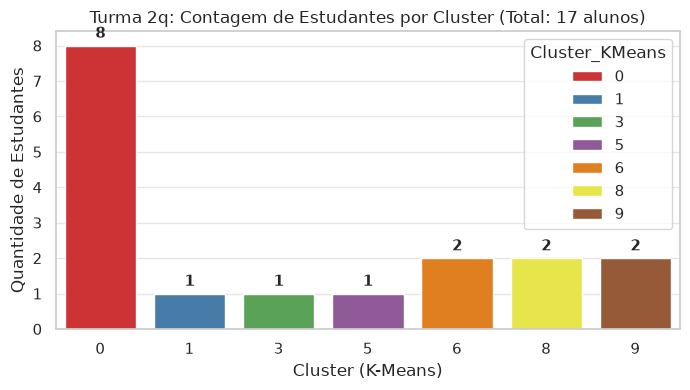

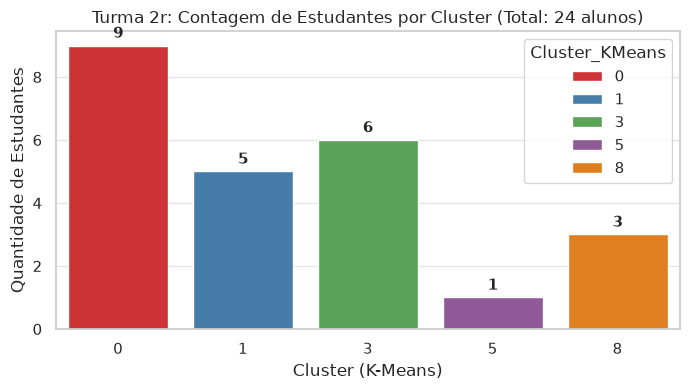

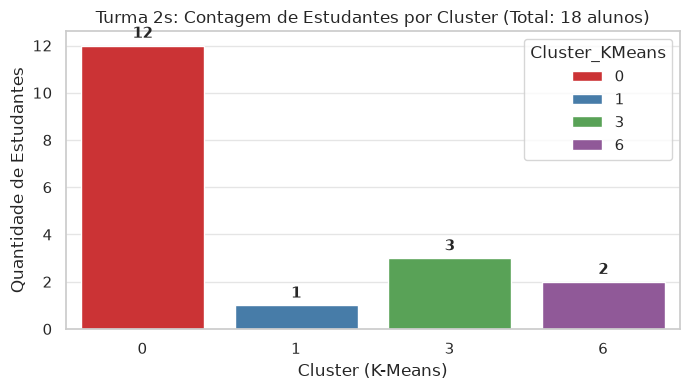

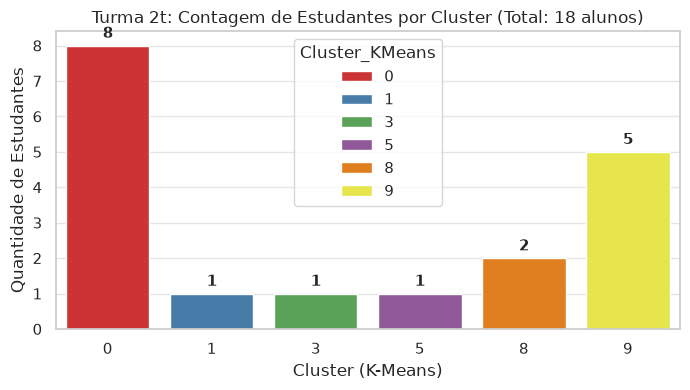


--> A gerar gráficos finais de estudantes Suspeitos vs. Não Suspeitos dentro de cada cluster...


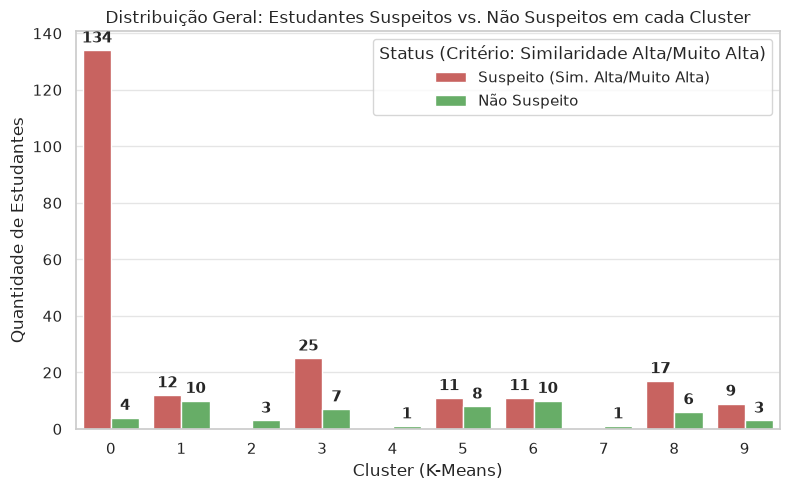

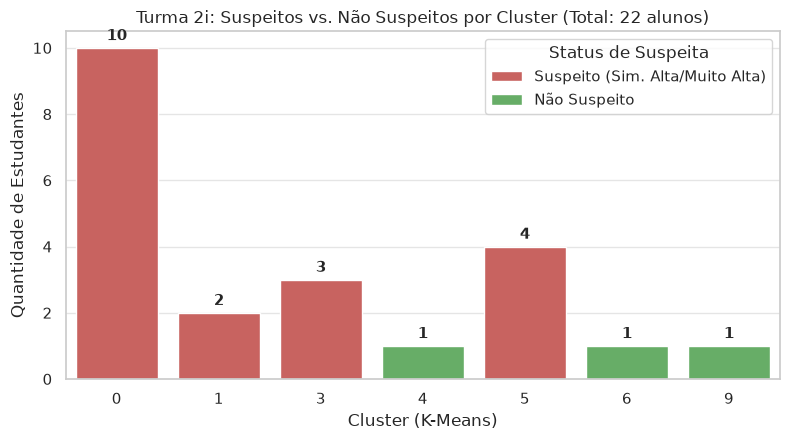

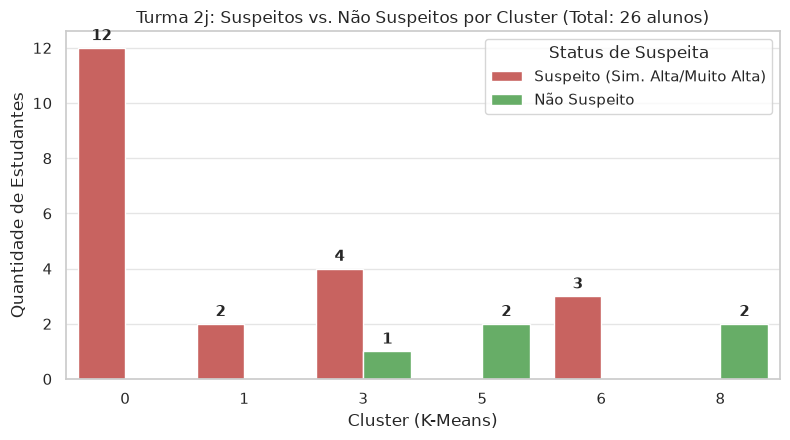

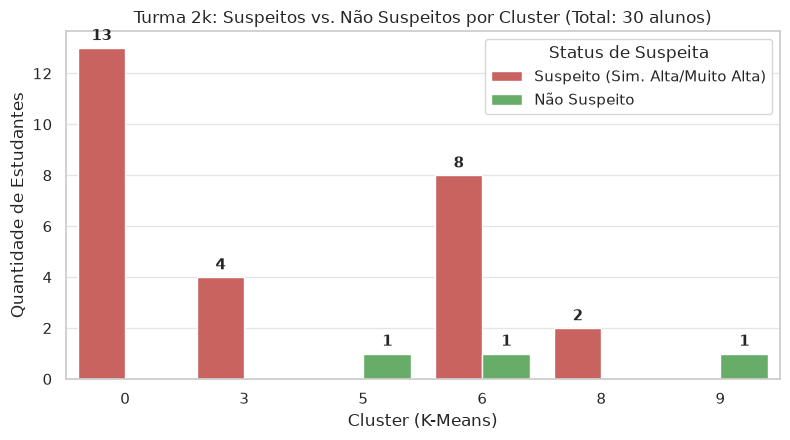

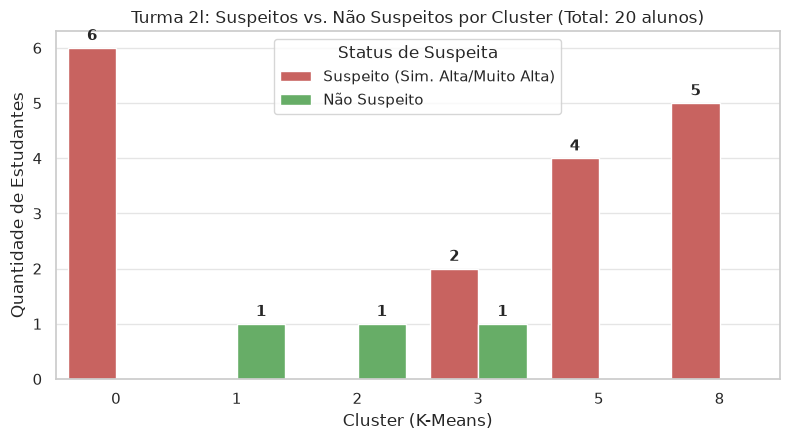

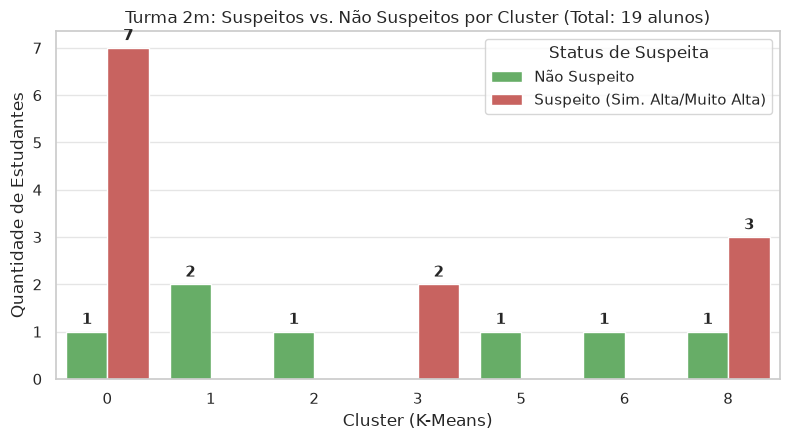

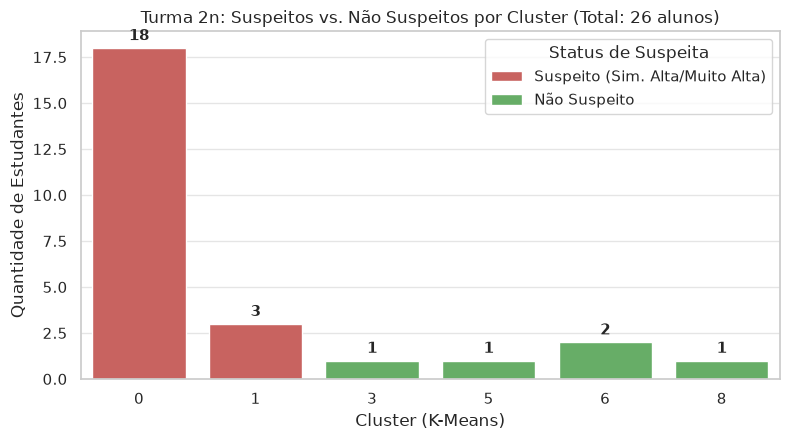

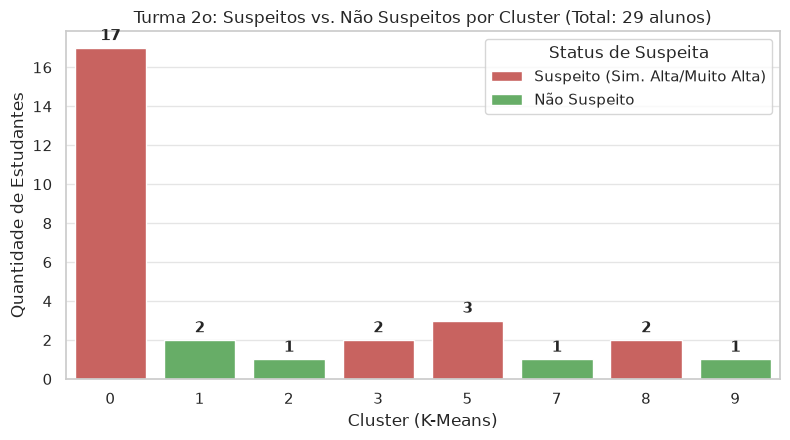

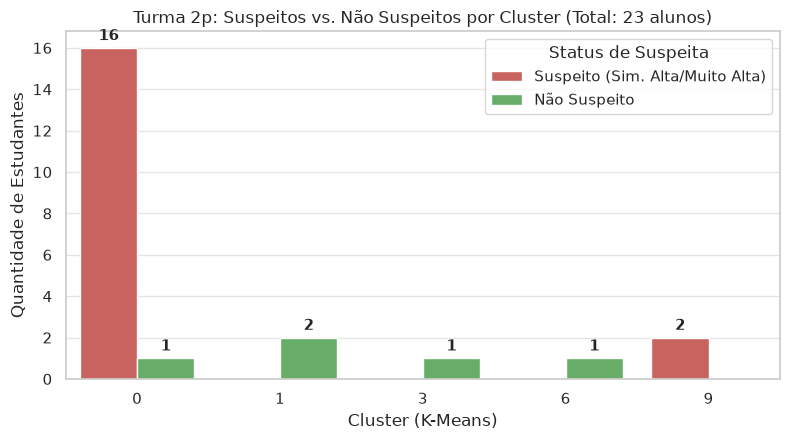

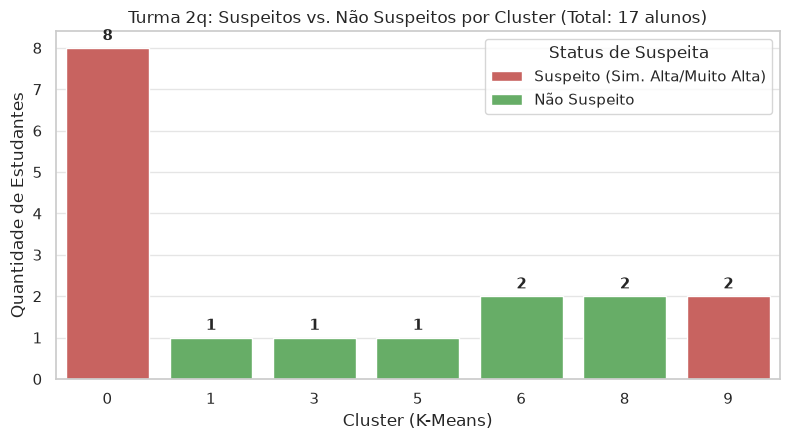

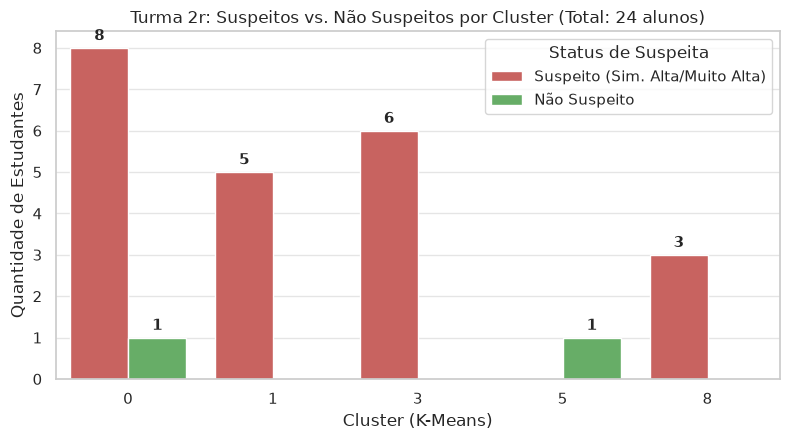

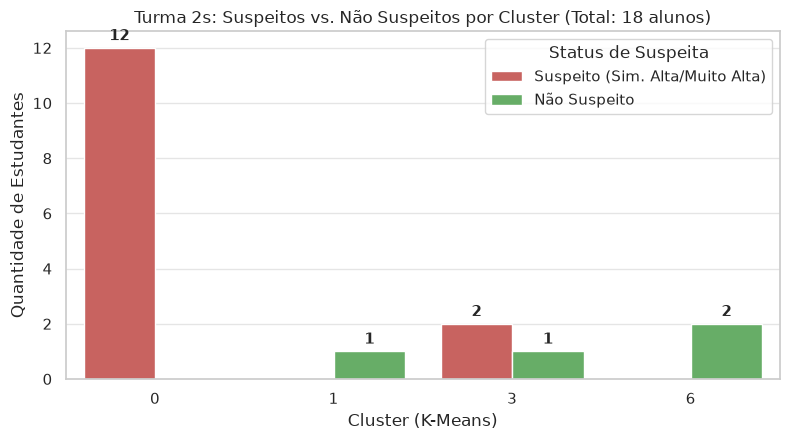

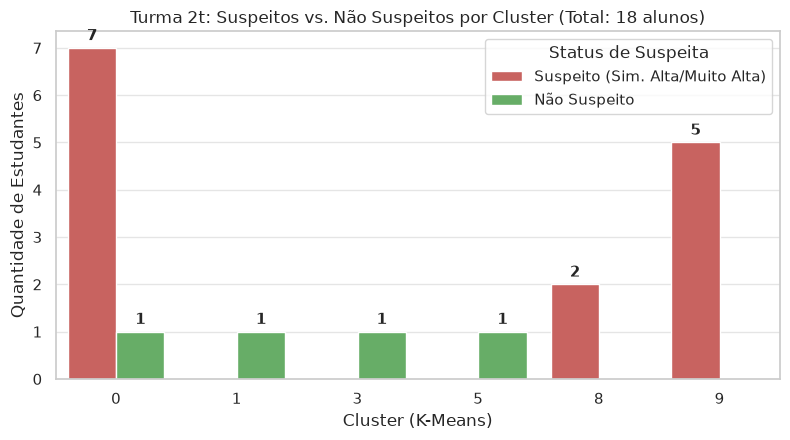

In [2]:
# ==============================================================================
# PIPELINE COMPLETO DE ANÁLISE DE RESPOSTAS E DETEÇÃO DE SUSPEITA DE COLA
# (COM GRÁFICOS ORIGINAIS + GRÁFICO FINAL DE SUSPEITOS/NÃO SUSPEITOS POR CLUSTER)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform

# ------------------------------------------------------------------------------
# 1. Configuração do Ambiente e Carregamento dos Dados
# ------------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

# Tenta carregar o ficheiro de dados disponível
file_path = 'data/prova_mat.csv'
try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    try:
        file_path = 'prova_cn_2.csv'
        df = pd.read_csv(file_path)
    except FileNotFoundError:
        file_path = 'prova_cn.csv'
        df = pd.read_csv(file_path)

# FILTRO: Desconsiderar turmas que possuem apenas 1 estudante
if 'serie_turma' in df.columns:
    contagem_alunos = df['serie_turma'].value_counts()
    turmas_validas = contagem_alunos[contagem_alunos > 1].index
    df = df[df['serie_turma'].isin(turmas_validas)].reset_index(drop=True)

print(f"--> Ficheiro carregado com sucesso: '{file_path}'")
print(f"--> Total de estudantes registados (turmas com > 1 aluno): {df.shape[0]}\n")

# ------------------------------------------------------------------------------
# 2. Pré-processamento e Codificação One-Hot Encoding
# ------------------------------------------------------------------------------
# Seleção das colunas correspondentes às questões (0 a 28)
question_cols = [str(i) for i in range(29) if str(i) in df.columns]

# Matriz de respostas tratadas
answers_df = df[question_cols].fillna(-1).astype(int)

# Representação das alternativas por One-Hot Encoding
encoder = OneHotEncoder(sparse_output=False)
X_ohe = encoder.fit_transform(answers_df)

print(f"Dimensão original das respostas: {answers_df.shape}")
print(f"Dimensão após One-Hot Encoding: {X_ohe.shape}\n")

# ------------------------------------------------------------------------------
# 3. Agrupamento K-Means e Seleção de K via Silhouette Score
# ------------------------------------------------------------------------------
silhouette_scores = []
k_range = list(range(2, 11))

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_ohe)
    score = silhouette_score(X_ohe, labels)
    silhouette_scores.append(score)

# Identificação do K com maior Silhouette Score
best_k_idx = np.argmax(silhouette_scores)
best_k = k_range[best_k_idx]

# Lógica para exibição do gráfico da Silhueta:
# - Se o melhor K for o primeiro (índice 0), exibe a partir dele e os posteriores.
# - Se for intermediário, exibe valores anteriores, o melhor K e os posteriores.
if best_k_idx == 0:
    plot_k = k_range
    plot_scores = silhouette_scores
    print(f"O melhor K ({best_k}) é o primeiro valor avaliado. Exibindo K={best_k} e valores posteriores.")
else:
    plot_k = k_range
    plot_scores = silhouette_scores
    print(f"O melhor K ({best_k}) é intermediário. Exibindo valores anteriores, K={best_k} e posteriores.")

# Gráfico da curva do Silhouette Score (MANTIDO)
plt.figure(figsize=(8, 4))
plt.plot(plot_k, plot_scores, marker='o', color='navy', linewidth=2)
plt.axvline(x=best_k, color='red', linestyle='--', label=f'Melhor K = {best_k} (Silhouette: {silhouette_scores[best_k_idx]:.3f})')
plt.title('Escolha do K no K-Means via Silhouette Score')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(plot_k)
plt.legend()
plt.tight_layout()
plt.show()

# Aplicação do K-Means definitivo
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans_final.fit_predict(X_ohe)

print(f"Clusters atribuídos aos estudantes com K = {best_k}.\n")

# ------------------------------------------------------------------------------
# 4. Cálculo da Distância de Hamming (Divergência de Respostas)
# ------------------------------------------------------------------------------
num_questoes = len(question_cols)

# Matriz de distância de Hamming normalizada [0.0 a 1.0]
hamming_norm_matrix = squareform(pdist(answers_df.values, metric='hamming'))

# Conversão para contagem absoluta de questões divergentes entre pares
hamming_count_matrix = np.round(hamming_norm_matrix * num_questoes).astype(int)

# ------------------------------------------------------------------------------
# 5. Identificação de Pares Suspeitos (RESTRITO AO MESMO GRUPO E MESMA TURMA)
# ------------------------------------------------------------------------------
n_estudantes = len(df)
pares_suspeitos = []

# Limiar de alerta para Similaridade Alta/Muito Alta: até 2 questões divergentes
MAX_DIVERGENCIA_QUESTOES = 2

for i in range(n_estudantes):
    for j in range(i + 1, n_estudantes):
        # FILTRO ESTRITO: Compara APENAS estudantes do MESMO CLUSTER/GRUPO e da MESMA TURMA
        mesmo_cluster = (df.loc[i, 'cluster_kmeans'] == df.loc[j, 'cluster_kmeans'])
        mesma_turma = (df.loc[i, 'serie_turma'] == df.loc[j, 'serie_turma']) if 'serie_turma' in df.columns else True

        if not (mesmo_cluster and mesma_turma):
            continue

        q_diff = hamming_count_matrix[i, j]

        # Classificação do nível de similaridade
        if q_diff == 0:
            nivel_similaridade = "Muito Alta (0 divergências)"
        elif q_diff <= MAX_DIVERGENCIA_QUESTOES:
            nivel_similaridade = "Alta (1 a 2 divergências)"
        else:
            nivel_similaridade = "Média/Baixa (>2 divergências)"

        if q_diff <= MAX_DIVERGENCIA_QUESTOES:
            pares_suspeitos.append({
                'Estudante_1': df.loc[i, 'estudante'],
                'Estudante_2': df.loc[j, 'estudante'],
                'Par_Estudantes': f"{df.loc[i, 'estudante']} - {df.loc[j, 'estudante']}",
                'Turma': df.loc[i, 'serie_turma'] if 'serie_turma' in df.columns else 'N/A',
                'Cluster_KMeans': df.loc[i, 'cluster_kmeans'],
                'Questoes_Divergentes': q_diff,
                'Nivel_Similaridade': nivel_similaridade,
                'Pontuacao_1': df.loc[i, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A',
                'Pontuacao_2': df.loc[j, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A'
            })

df_suspeitos = pd.DataFrame(pares_suspeitos)

if not df_suspeitos.empty:
    df_suspeitos = df_suspeitos.sort_values(by=['Turma', 'Cluster_KMeans', 'Questoes_Divergentes'])
    print("=========================================================")
    print(f"  PARES DO MESMO GRUPO/TURMA COM INDÍCIOS SUSPEITOS DE COLA: {len(df_suspeitos)}")
    print("=========================================================\n")
    display(df_suspeitos)
else:
    print("Nenhum par do mesmo grupo/turma atendeu aos critérios de suspeita estabelecidos.\n")

# ------------------------------------------------------------------------------
# 6. GERAÇÃO DE GRÁFICOS DE BARRAS DA CONTABILIDADE DE CLUSTERS POR TURMA (MANTIDOS)
# ------------------------------------------------------------------------------
turmas_unicas = sorted(df['serie_turma'].unique()) if 'serie_turma' in df.columns else ['N/A']

print("--> A gerar gráficos de barras de distribuição por cluster para cada turma validada (>1 aluno)...")

for turma in turmas_unicas:
    df_turma = df[df['serie_turma'] == turma] if 'serie_turma' in df.columns else df

    if len(df_turma) <= 1:
        continue

    plt.figure(figsize=(7, 4))

    cluster_counts = df_turma['cluster_kmeans'].value_counts().reset_index()
    cluster_counts.columns = ['Cluster_KMeans', 'Quantidade_Alunos']
    cluster_counts = cluster_counts.sort_values('Cluster_KMeans')

    ax = sns.barplot(
        data=cluster_counts,
        x='Cluster_KMeans',
        hue='Cluster_KMeans',
        y='Quantidade_Alunos',
        palette='Set1'
    )

    plt.title(f'Turma {turma}: Contagem de Estudantes por Cluster (Total: {len(df_turma)} alunos)')
    plt.xlabel('Cluster (K-Means)')
    plt.ylabel('Quantidade de Estudantes')

    for p in ax.patches:
        height = int(p.get_height()) if not np.isnan(p.get_height()) else 0
        if height > 0:
            ax.annotate(f'{height}',
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom',
                        fontsize=11, fontweight='bold',
                        xytext=(0, 3), textcoords='offset points')

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------------------------
# 7. ADICIONADO: GRÁFICOS DE ESTUDANTES SUSPEITOS VS. NÃO SUSPEITOS POR CLUSTER
# (CRITÉRIO: SIMILARIDADE ALTA E MUITO ALTA)
# ------------------------------------------------------------------------------
# Identificação individual dos estudantes envolvidos em pares com similaridade Alta/Muito Alta
if not df_suspeitos.empty:
    estudantes_suspeitos_set = set(df_suspeitos['Estudante_1']).union(set(df_suspeitos['Estudante_2']))
else:
    estudantes_suspeitos_set = set()

# Atribuição da coluna de status
df['Status_Suspeita'] = df['estudante'].apply(
    lambda x: 'Suspeito (Sim. Alta/Muito Alta)' if x in estudantes_suspeitos_set else 'Não Suspeito'
)

print("\n--> A gerar gráficos finais de estudantes Suspeitos vs. Não Suspeitos dentro de cada cluster...")

# 7.1 Gráfico Geral por Cluster
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df,
    x='cluster_kmeans',
    hue='Status_Suspeita',
    palette={'Suspeito (Sim. Alta/Muito Alta)': '#d9534f', 'Não Suspeito': '#5cb85c'}
)

plt.title('Distribuição Geral: Estudantes Suspeitos vs. Não Suspeitos em cada Cluster')
plt.xlabel('Cluster (K-Means)')
plt.ylabel('Quantidade de Estudantes')
plt.legend(title='Status (Critério: Similaridade Alta/Muito Alta)')

for p in ax.patches:
    height = int(p.get_height()) if not np.isnan(p.get_height()) else 0
    if height > 0:
        ax.annotate(f'{height}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=11, fontweight='bold',
                    xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

# 7.2 Gráficos Detalhados por Turma e Cluster
for turma in turmas_unicas:
    df_turma = df[df['serie_turma'] == turma] if 'serie_turma' in df.columns else df

    if len(df_turma) <= 1:
        continue

    plt.figure(figsize=(8, 4.5))
    ax = sns.countplot(
        data=df_turma,
        x='cluster_kmeans',
        hue='Status_Suspeita',
        palette={'Suspeito (Sim. Alta/Muito Alta)': '#d9534f', 'Não Suspeito': '#5cb85c'}
    )

    plt.title(f'Turma {turma}: Suspeitos vs. Não Suspeitos por Cluster (Total: {len(df_turma)} alunos)')
    plt.xlabel('Cluster (K-Means)')
    plt.ylabel('Quantidade de Estudantes')
    plt.legend(title='Status de Suspeita')

    for p in ax.patches:
        height = int(p.get_height()) if not np.isnan(p.get_height()) else 0
        if height > 0:
            ax.annotate(f'{height}',
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom',
                        fontsize=11, fontweight='bold',
                        xytext=(0, 3), textcoords='offset points')

    plt.tight_layout()
    plt.show()

In [9]:
# ==============================================================================
# ETAPA: ANÁLISE DE PROXIMIDADE DO HORÁRIO DE ENTREGA E TABELA POR TURMA
# ==============================================================================

import pandas as pd
import numpy as np

# 1. Conversão da coluna de horário de entrega para o formato datetime
if 'datetime' in df.columns:
    df['datetime'] = pd.to_datetime(df['datetime'])

# 2. Definição dos limiares de tempo e de divergência no gabarito
MAX_MINUTOS_ENTREGA = 5.0  # Janela máxima de 5 minutos entre entregas
MAX_DIVERGENCIA_QUESTOES = 2

n_estudantes = len(df)
pares_entrega_proxima = []

# 3. Comparação par a par de estudantes da mesma turma e do mesmo cluster
for i in range(n_estudantes):
    for j in range(i + 1, n_estudantes):
        mesmo_cluster = (df.loc[i, 'cluster_kmeans'] == df.loc[j, 'cluster_kmeans'])
        mesma_turma = (df.loc[i, 'serie_turma'] == df.loc[j, 'serie_turma']) if 'serie_turma' in df.columns else True

        if mesmo_cluster and mesma_turma:
            t_i = df.loc[i, 'datetime']
            t_j = df.loc[j, 'datetime']

            if pd.notnull(t_i) and pd.notnull(t_j):
                diff_segundos = abs((t_i - t_j).total_seconds())
                diff_minutos = diff_segundos / 60.0
                q_diff = hamming_count_matrix[i, j]

                # Seleciona apenas entregas dentro da janela limite de tempo (<= 5 min)
                if diff_minutos <= MAX_MINUTOS_ENTREGA:
                    pares_entrega_proxima.append({
                        'Par_Estudantes': f"{df.loc[i, 'estudante']} - {df.loc[j, 'estudante']}",
                        'Turma': df.loc[i, 'serie_turma'] if 'serie_turma' in df.columns else 'N/A',
                        'Horario_1': t_i.strftime('%Y-%m-%d %H:%M:%S'),
                        'Horario_2': t_j.strftime('%Y-%m-%d %H:%M:%S'),
                        'Diferenca_Tempo': f"{int(diff_segundos)}s" if diff_segundos < 60 else f"{diff_minutos:.1f} min",
                        'Questoes_Divergentes': q_diff,
                        'Suspeita_Gabarito': 'Alta/Muito Alta (<=2 diff)' if q_diff <= MAX_DIVERGENCIA_QUESTOES else 'Baixa (>2 diff)'
                    })

# 4. Geração e exibição de tabelas individuais separadas por turma
df_entrega_proxima = pd.DataFrame(pares_entrega_proxima)

if not df_entrega_proxima.empty:
    turmas_unicas = sorted(df_entrega_proxima['Turma'].unique())

    print("=========================================================")
    print(f" RELATÓRIO DE PARES COM HORÁRIO PRÓXIMO (<= {MAX_MINUTOS_ENTREGA} min) POR TURMA")
    print("=========================================================\n")

    for turma in turmas_unicas:
        # Filtra os dados da turma atual e ordena por horário
        df_turma = df_entrega_proxima[df_entrega_proxima['Turma'] == turma].sort_values(by=['Horario_1', 'Questoes_Divergentes'])

        print(f"---------------------------------------------------------")
        print(f" TURMA: {turma} (Total de pares suspeitos: {len(df_turma)})")
        print(f"---------------------------------------------------------")

        display(df_turma)
        print("\n")
else:
    print("Nenhum par realizou a entrega dentro da janela de tempo especificada.")

 RELATÓRIO DE PARES COM HORÁRIO PRÓXIMO (<= 5.0 min) POR TURMA

---------------------------------------------------------
 TURMA: 2e (Total de pares suspeitos: 9)
---------------------------------------------------------


,Par_Estudantes,Turma,Horario_1,Horario_2,Diferenca_Tempo,Questoes_Divergentes,Suspeita_Gabarito
4,870 - 564,2e,2025-07-17 16:17:31,2025-07-17 16:20:53,3.4 min,2,Alta/Muito Alta (<=2 diff)
5,833 - 996,2e,2025-07-17 19:07:07,2025-07-17 19:09:30,2.4 min,8,Baixa (>2 diff)
8,667 - 1297,2e,2025-07-17 19:25:01,2025-07-17 19:27:52,2.9 min,1,Alta/Muito Alta (<=2 diff)
1,83 - 667,2e,2025-07-17 19:29:57,2025-07-17 19:25:01,4.9 min,0,Alta/Muito Alta (<=2 diff)
2,83 - 1297,2e,2025-07-17 19:29:57,2025-07-17 19:27:52,2.1 min,1,Alta/Muito Alta (<=2 diff)
0,83 - 2,2e,2025-07-17 19:29:57,2025-07-17 19:32:01,2.1 min,2,Alta/Muito Alta (<=2 diff)
6,2 - 1297,2e,2025-07-17 19:32:01,2025-07-17 19:27:52,4.2 min,3,Baixa (>2 diff)
3,507 - 148,2e,2025-07-17 21:30:28,2025-07-17 21:30:28,0s,0,Alta/Muito Alta (<=2 diff)
7,897 - 791,2e,2025-07-17 23:29:05,2025-07-17 23:28:33,32s,4,Baixa (>2 diff)




---------------------------------------------------------
 TURMA: 2f (Total de pares suspeitos: 15)
---------------------------------------------------------


,Par_Estudantes,Turma,Horario_1,Horario_2,Diferenca_Tempo,Questoes_Divergentes,Suspeita_Gabarito
11,380 - 1296,2f,2025-07-17 08:26:56,2025-07-17 08:28:09,1.2 min,3,Baixa (>2 diff)
12,380 - 877,2f,2025-07-17 08:26:56,2025-07-17 08:27:25,29s,3,Baixa (>2 diff)
13,380 - 1195,2f,2025-07-17 08:26:56,2025-07-17 08:30:08,3.2 min,3,Baixa (>2 diff)
14,380 - 416,2f,2025-07-17 08:26:56,2025-07-17 08:28:03,1.1 min,3,Baixa (>2 diff)
21,877 - 1195,2f,2025-07-17 08:27:25,2025-07-17 08:30:08,2.7 min,2,Alta/Muito Alta (<=2 diff)
22,877 - 416,2f,2025-07-17 08:27:25,2025-07-17 08:28:03,38s,2,Alta/Muito Alta (<=2 diff)
18,1296 - 1195,2f,2025-07-17 08:28:09,2025-07-17 08:30:08,2.0 min,0,Alta/Muito Alta (<=2 diff)
19,1296 - 416,2f,2025-07-17 08:28:09,2025-07-17 08:28:03,6s,0,Alta/Muito Alta (<=2 diff)
17,1296 - 877,2f,2025-07-17 08:28:09,2025-07-17 08:27:25,44s,2,Alta/Muito Alta (<=2 diff)
23,1195 - 416,2f,2025-07-17 08:30:08,2025-07-17 08:28:03,2.1 min,0,Alta/Muito Alta (<=2 diff)




---------------------------------------------------------
 TURMA: 2g (Total de pares suspeitos: 17)
---------------------------------------------------------


,Par_Estudantes,Turma,Horario_1,Horario_2,Diferenca_Tempo,Questoes_Divergentes,Suspeita_Gabarito
25,46 - 1521,2g,2025-07-17 16:40:12,2025-07-17 16:43:40,3.5 min,4,Baixa (>2 diff)
26,46 - 247,2g,2025-07-17 16:40:12,2025-07-17 16:43:38,3.4 min,4,Baixa (>2 diff)
35,1521 - 247,2g,2025-07-17 16:43:40,2025-07-17 16:43:38,2s,0,Alta/Muito Alta (<=2 diff)
34,1521 - 548,2g,2025-07-17 16:43:40,2025-07-17 16:47:00,3.3 min,1,Alta/Muito Alta (<=2 diff)
38,548 - 247,2g,2025-07-17 16:47:00,2025-07-17 16:43:38,3.4 min,1,Alta/Muito Alta (<=2 diff)
31,754 - 81,2g,2025-07-17 17:56:26,2025-07-17 17:51:56,4.5 min,5,Baixa (>2 diff)
37,1672 - 90,2g,2025-07-17 18:56:48,2025-07-17 19:00:18,3.5 min,2,Alta/Muito Alta (<=2 diff)
39,90 - 508,2g,2025-07-17 19:00:18,2025-07-17 19:02:34,2.3 min,2,Alta/Muito Alta (<=2 diff)
29,814 - 508,2g,2025-07-17 19:02:42,2025-07-17 19:02:34,8s,0,Alta/Muito Alta (<=2 diff)
27,814 - 1404,2g,2025-07-17 19:02:42,2025-07-17 19:02:54,12s,1,Alta/Muito Alta (<=2 diff)




---------------------------------------------------------
 TURMA: 2h (Total de pares suspeitos: 2)
---------------------------------------------------------


,Par_Estudantes,Turma,Horario_1,Horario_2,Diferenca_Tempo,Questoes_Divergentes,Suspeita_Gabarito
41,354 - 945,2h,2025-07-17 21:17:34,2025-07-17 21:13:30,4.1 min,1,Alta/Muito Alta (<=2 diff)
42,872 - 165,2h,2025-07-17 22:01:00,2025-07-17 22:01:01,1s,0,Alta/Muito Alta (<=2 diff)
